# HW1 — Statistical inference and supervised learning

**EE-411 — Fundamentals of Inference and Learning, 2026–2027**

**Learning objectives**
- Derive and compare estimators, quantify uncertainty, and interpret their limits.
- Fit and compare classifiers using cross-validation and a final test set.
- Diagnose class imbalance and apply resampling without leaking validation data.

**Prerequisites:** probability densities, likelihood, basic Bayesian inference, Fisher
information, classification, and Python/NumPy. Required packages are listed in
`requirements.txt`. Open this notebook with `HW1/` as the working directory.

**Working period:** approximately three weeks. The two parts are independent;
plan time for both mathematical reasoning and numerical experiments.

Submit your completed exercise notebook on Moodle by the announced deadline.
Each student submits their own work. AI tools may be used, but you are responsible
for checking and explaining every result. Briefly document how you used them.
Questions marked **optional** are extensions; the remaining questions form the core.

Put mathematical and written answers in the answer slots (you may use
`display(Markdown(r"..."))`), together with the requested code. Explain results;
tables or scores without interpretation are not complete answers. Run your
notebook from a fresh kernel before submitting it.

Use the supplied data; you do not need to download images or run the generators.
We use a fixed random seed (`SEED`) so that random operations give reproducible
results across runs. Setting `random_state=SEED` uses this fixed seed. A seed fixes
one realization, not a universal estimator or classifier ranking.

In [1]:
# PROVIDED: common imports and reproducibility settings.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED = 2203
plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True})

## Part I — Statistical inference and estimation

Alex encodes the first two and last two digits of a phone code as parameters
$a$ and $b$. For $0<a<b$, consider the triangular density

$$p(x;a,b)=H(a,b)\begin{cases}
x/a,&0\leq x\leq a,\\
(b-x)/(b-a),&a<x\leq b,\\
0,&\text{otherwise}.
\end{cases}$$

We first treat the parameters as continuous. At the end, discuss the additional
constraint that a code consists of integer pairs. The files in this part reproduce
the current 2026 HW1 data. Do not inspect `generator.py` to obtain the answers.

### Question 1 — Normalization and expectation

Find $H(a,b)$ and derive the mean $\mu=\mathbb E[X]$. Show the integrals.

In [71]:
# TODO: answer Question 1, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 
display(Markdown(r"""
#### 1. Find \(H(a,b)\)
Since \(p(x;a,b)\) is a probability density function, it must satisfy

$$
\int_{-\infty}^{+\infty}p(x;a,b)\,dx=1
$$

Therefore,

$$
H(a,b)\left(
\int_0^a\frac{x}{a}\,dx+
\int_a^b\frac{b-x}{b-a}\,dx
\right)=1
$$

Computing the two integrals we obtain,

$$
\int_0^a\frac{x}{a}\,dx
=\frac1a\left[\frac{x^2}{2}\right]_0^a
=\frac a2
$$

$$
\int_a^b\frac{b-x}{b-a}\,dx
=\frac1{b-a}\left[bx-\frac{x^2}{2}\right]_a^b
=\frac{b-a}{2}
$$

Hence,

$$
H(a,b)\left(\frac a2+\frac{b-a}{2}\right)=1
$$

so

$$
H(a,b)\frac b2=1
$$

Thus, the normalization constant is

$$
\boxed{H(a,b)=\frac2b}
$$

#### 2. Derive the mean $\mu=\mathbb E[X]$

By definition,

$$
\mu=\mathbb E[X]
=\int_{-\infty}^{+\infty}x\,p(x;a,b)\,dx
$$

In our case we have,

$$
\mu=\frac2b\left(
\int_0^a\frac{x^2}{a}\,dx+
\int_a^b\frac{x(b-x)}{b-a}\,dx
\right)
$$

The first integral is

$$
\int_0^a\frac{x^2}{a}\,dx
=\frac1a\left[\frac{x^3}{3}\right]_0^a
=\frac{a^2}{3}
$$

The second integral is

$$
\int_a^b\frac{x(b-x)}{b-a}\,dx
=\frac1{b-a}\int_a^b(bx-x^2)\,dx
=\frac1{b-a}\left[\frac{bx^2}{2}-\frac{x^3}{3}\right]_a^b
=\frac{b^2+ab-2a^2}{6}
$$

Combining the results,

$$
\mu
=\frac2b\left(
\frac{a^2}{3}+\frac{b^2+ab-2a^2}{6}
\right)
=\frac2b\cdot\frac{b^2+ab}{6}
=\frac{a+b}{3}
$$

Therefore, the mean is

$$
\boxed{\mathbb E[X]=\mu=\frac{a+b}{3}}
$$
"""))


#### 1. Find \(H(a,b)\)
Since \(p(x;a,b)\) is a probability density function, it must satisfy

$$
\int_{-\infty}^{+\infty}p(x;a,b)\,dx=1
$$

Therefore,

$$
H(a,b)\left(
\int_0^a\frac{x}{a}\,dx+
\int_a^b\frac{b-x}{b-a}\,dx
\right)=1
$$

Computing the two integrals we obtain,

$$
\int_0^a\frac{x}{a}\,dx
=\frac1a\left[\frac{x^2}{2}\right]_0^a
=\frac a2
$$

$$
\int_a^b\frac{b-x}{b-a}\,dx
=\frac1{b-a}\left[bx-\frac{x^2}{2}\right]_a^b
=\frac{b-a}{2}
$$

Hence,

$$
H(a,b)\left(\frac a2+\frac{b-a}{2}\right)=1
$$

so

$$
H(a,b)\frac b2=1
$$

Thus, the normalization constant is

$$
\boxed{H(a,b)=\frac2b}
$$

#### 2. Derive the mean $\mu=\mathbb E[X]$

By definition,

$$
\mu=\mathbb E[X]
=\int_{-\infty}^{+\infty}x\,p(x;a,b)\,dx
$$

In our case we have,

$$
\mu=\frac2b\left(
\int_0^a\frac{x^2}{a}\,dx+
\int_a^b\frac{x(b-x)}{b-a}\,dx
\right)
$$

The first integral is

$$
\int_0^a\frac{x^2}{a}\,dx
=\frac1a\left[\frac{x^3}{3}\right]_0^a
=\frac{a^2}{3}
$$

The second integral is

$$
\int_a^b\frac{x(b-x)}{b-a}\,dx
=\frac1{b-a}\int_a^b(bx-x^2)\,dx
=\frac1{b-a}\left[\frac{bx^2}{2}-\frac{x^3}{3}\right]_a^b
=\frac{b^2+ab-2a^2}{6}
$$

Combining the results,

$$
\mu
=\frac2b\left(
\frac{a^2}{3}+\frac{b^2+ab-2a^2}{6}
\right)
=\frac2b\cdot\frac{b^2+ab}{6}
=\frac{a+b}{3}
$$

Therefore, the mean is

$$
\boxed{\mathbb E[X]=\mu=\frac{a+b}{3}}
$$


#### 1. Find \(H(a,b)\)

Since \(p(x;a,b)\) is a probability density function, it must satisfy


$$\int_{-\infty}^{+\infty}p(x;a,b)\,dx=1$$


Therefore,

$$
H(a,b)\left(
\int_0^a\frac{x}{a}\,dx+
\int_a^b\frac{b-x}{b-a}\,dx
\right)=1
$$

Computing the two integrals we obtain,

$$
\int_0^a\frac{x}{a}\,dx
=\frac1a\left[\frac{x^2}{2}\right]_0^a
=\frac a2 $$

$$\int_a^b\frac{b-x}{b-a}\,dx
=\frac1{b-a}\left[bx-\frac{x^2}{2}\right]_a^b
=\frac{b-a}{2}
$$

Hence,

$$
H(a,b)\left(\frac a2+\frac{b-a}{2}\right)=1
$$

so

$$
H(a,b)\frac b2=1
$$

Thus, the normalization constant is

$$
\boxed{H(a,b)=\frac2b}
$$

#### 2. Derive the mean $\mu=\mathbb E[X]$

By definition,

$$
\mu=\mathbb E[X]
=\int_{-\infty}^{+\infty}x\,p(x;a,b)\,dx
$$

In our case we have,

$$
\mu=\frac2b\left(
\int_0^a\frac{x^2}{a}\,dx+
\int_a^b\frac{x(b-x)}{b-a}\,dx
\right)
$$

The first integral is

$$
\int_0^a\frac{x^2}{a}\,dx
=\frac1a\left[\frac{x^3}{3}\right]_0^a
=\frac{a^2}{3}
$$

The second integral is

$$
\int_a^b\frac{x(b-x)}{b-a}\,dx
=\frac1{b-a}\int_a^b(bx-x^2)\,dx
=\frac1{b-a}\left[\frac{bx^2}{2}-\frac{x^3}{3}\right]_a^b
=\frac{b^2+ab-2a^2}{6}
$$

Combining the results,

$$\
\mu
=\frac2b\left(
\frac{a^2}{3}+\frac{b^2+ab-2a^2}{6}
\right)
=\frac2b\cdot\frac{b^2+ab}{6}
=\frac{a+b}{3}
$$

Therefore, the mean is

$$
\boxed{\mathbb E[X]=\mu=\frac{a+b}{3}}
$$

### Question 2 — CDF, median, and mode

Derive the cumulative distribution function $F(t)=\Pr(X\leq t)$ and the median
$m$. Distinguish the cases $a\leq b/2$ and $a>b/2$. Compare the mean, median,
and mode, including the symmetric case.

In [4]:
# TODO: answer Question 2, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: ...

#### 1. Cumulative distribution function

The cumulative distribution function is defined by

$$
F(t)=P(X\leq t)=\int_{-\infty}^{t}p(x;a,b)\,dx.
$$

For $t<0$,

$$
F(t)=0
$$

For $0\leq t\leq a$,

$$
F(t)
=\frac2b\int_0^t\frac{x}{a}\,dx
=\frac{2}{ab}\left[\frac{x^2}{2}\right]_0^t
=\frac{t^2}{ab}
$$

For $a<t\leq b$,

$$
F(t)
=\int_0^a p(x;a,b),dx+\int_a^t p(x;a,b),dx\
=\frac{a}{b}+\frac2b\int_a^t\frac{b-x}{b-a},dx
=\frac{a}{b}+\frac{2}{b(b-a)}
=\frac{a}{b}+\frac2b\int_a^t\frac{b-x}{b-a}\,dx
=\frac{a}{b}+\frac{2}{b(b-a)}
\left[bx-\frac{x^2}{2}\right]_a^t
=1-\frac{(b-t)^2}{b(b-a)}
$$

For $t>b$, 
$$F(t)=1$$

Therefore,

$$
F(t)=
\begin{cases}
0, & t<0,\\[4pt]
\dfrac{t^2}{ab}, & 0\leq t\leq a,\\[8pt]
1-\dfrac{(b-t)^2}{b(b-a)}, & a<t\leq b,\\[8pt]
1, & t>b.
\end{cases}
$$

#### 2. Median

The median $m$ satisfies $F(m)=1/2$.

**Case 1: $a\leq b/2$**

In this case, the median lies in the second interval, $a<m\leq b$. Thus,

$$
1-\frac{(b-m)^2}{b(b-a)}=\frac12
$$

Hence,

$$
(b-m)^2=\frac{b(b-a)}2
$$
$$
b-m=\sqrt{\frac{b(b-a)}2}
$$

Therefore,

$$
\boxed{m=b-\sqrt{\frac{b(b-a)}2}}
$$

**Case 2: $a>b/2$**

In this case, the median lies in the first interval, $0\leq m\leq a$. Thus,

$$
\frac{m^2}{ab}=\frac12
$$

Therefore,

$$
\boxed{m=\sqrt{\frac{ab}{2}}}
$$

#### 3. Mode and comparison with the mean and median

The density increases on $[0,a]$ and decreases on $[a,b]$. Its maximum occurs at $x=a$, so the mode is

$$
\operatorname{mode}=a
$$

From Question 1, the mean is

$$
\mu=\frac{a+b}{3}
$$

From question 2, the median is 
$$
m=
\begin{cases}
b-\sqrt{\dfrac{b(b-a)}{2}}, & a\leq \dfrac b2\\[8pt]
\sqrt{\dfrac{ab}{2}}, & a>\dfrac b2
\end{cases}
$$

Since $\mu-a=(b-2a)/3$, the mean is greater than, equal to, or less than the mode depending on whether $a<b/2$, $a=b/2$, or $a>b/2$. 
Thus, $\mu>a$ if $a<b/2$, $\mu=a$ if $a=b/2$, and $\mu<a$ if $a>b/2$.

To compare the median and the mode, we use $F(a)=a/b$. Since $F(m)=1/2$,

- If $a<b/2$, then $F(a)<1/2$, so $a<m$
- If $a=b/2$, then $F(a)=1/2$, so $a=m$
- If $a>b/2$, then $F(a)>1/2$, so $m<a$

Comparing the expressions for $m$ and $\mu$ gives the final ordering :

$$
\boxed{
\begin{cases}
a<m<\mu, & a<b/2\\[4pt]
a=m=\mu=b/2, & a=b/2\\[4pt]
\mu<m<a, & a>b/2
\end{cases}
}
$$

When $a=b/2$, the density is symmetric about $b/2$, so the mean, median, and mode coincide.

Here is a summary table of all the different results :

| x | Left-skewed ($a>b/2$) | Symmetric ($a=b/2$) | Right-skewed ($a<b/2$) |
|---|---|---|---|
| Mode | $a$ | $a=b/2$ | $a$ |
| Median | $m=\sqrt{\frac{ab}{2}}$ | $m=b/2$ | $m=b-\sqrt{\frac{b(b-a)}{2}}$ |
| Mean | $\mu=\frac{a+b}{3}$ | $\mu=b/2$ | $\mu=\frac{a+b}{3}$ |
| Comments | $\mu<m<\text{mode}$ | $\mu=m=\text{mode}$ | $\text{mode}<m<\mu$ |

### Question 3 — Implement the density and inspect the sample

For the file `fixed_b.npy`, $b=20$ is known. Implement `pdf(x, a, b=20)`.
Load the data, report its size, empirical mean and median, and plot a density
histogram with a density curve for an admissible $a$ of your choice.
Label the figure. Do not assume that your chosen plotting value is the true $a$.

Sample size: 100
Empirical mean: 10.739751742853539
Empirical median: 10.700494688840413


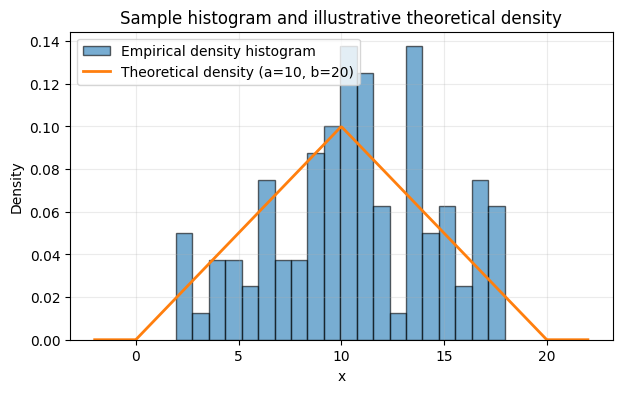

In [45]:
# TODO: answer Question 3, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

def pdf(x, a, b=20):
    H = 2 / b
    left = x / a
    right = (b - x) / (b - a)

    pdf = H * np.where(
                        (x >= 0) & (x <= a), left, 
                        np.where((x > a) & (x <= b), right, 0))
    return pdf

# Sample loading
data = np.load("fixed_b.npy")

# Sample statistics
print("Sample size:", data.size)
print("Empirical mean:", np.mean(data))
print("Empirical median:", np.median(data))

# Plot density histogram and an illustrative density curve
b = 20
a_plot = 10  

x = np.linspace(0-2, b+2, 500)

plt.hist(data, bins=20, density=True, alpha=0.6,
         edgecolor="black", label="Empirical density histogram")
plt.plot(x, pdf(x, a_plot, b), linewidth=2,
         label=f"Theoretical density (a={a_plot}, b={b})")

plt.xlabel("x")
plt.ylabel("Density")
plt.title("Sample histogram and illustrative theoretical density")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

The function behaves as expected. The pdf is triangular with an area of 1 and is equal to zero outside $[0,b]$. The parameter a is set to 10 for this example.

### Question 4 — Mean and median estimators

Invert the expressions for the population mean and median to derive
$\hat a_{\mathrm{mean}}$ and $\hat a_{\mathrm{median}}$. Implement them and
evaluate them on the sample. Can finite-sample estimates fall outside $(0,b)$?
Use the untruncated formulas in the later MSE comparison and explain this choice.

#### 1. Mean Estimator

From question 1, the population mean of the triangular distribution is

$$
\mathbb{E}[X] = \mu = \frac{a+b}{3}
$$

By estimation we replace the population mean with the sample mean $\bar{X}$. This gives

$$
\bar{X} = \frac{a+b}{3}
$$

Solving for $a$, we obtain the mean-based estimator

$$
\boxed{\hat{a}_{\mathrm{mean}} = 3\bar{X} - b}
$$

#### 2. Median Estimator

From question 2, the median is

$$
m =
\begin{cases}
\sqrt{\dfrac{ab}{2}}, & \text{if } a >\dfrac{b}{2} \\[6pt]
b-\sqrt{\dfrac{b(b-a)}{2}}, & \text{if } a  \leq \dfrac{b}{2}
\end{cases}
$$

By estimation, we replace the population median with the sample median $\bar{M}$ and reverse the formula.

If $\bar{M} > b/2$, then

$$
\bar{M} = \sqrt{\frac{ab}{2}}
\quad \Longrightarrow \quad
\hat{a} = \frac{2\bar{M}^{2}}{b}
$$

If $\bar{M} \leq b/2$, then

$$
b-\bar{M} = \sqrt{\frac{b(b-a)}{2}}
$$

which gives

$$
\hat{a} = b-\frac{2(b-\bar{M})^{2}}{b}
$$

Therefore, the median-based estimator is

$$
\boxed{
\hat{a}_{\mathrm{median}} =
\begin{cases}
\dfrac{2\bar{M}^{2}}{b}, & \text{if } \bar{M} > \dfrac{b}{2} \\[8pt]
b-\dfrac{2(b-\bar{M})^{2}}{b}, & \text{if } \bar{M} \leq \dfrac{b}{2}
\end{cases}
}
$$

#### 3. Finite-Sample Estimates

The mean-based estimator is

$$
\hat a_{\mathrm{mean}}=3\bar X-b
$$

Since $0\leq \bar X\leq b$, this estimator can fall outside $(0,b)$ :

1. If $\bar X\leq b/3$, then $\hat a_{\mathrm{mean}}\leq 0$

2. If $\bar X\geq 2b/3$, then $\hat a_{\mathrm{mean}}\geq b$

Therefore, the mean-based estimator can produce estimates outside the parameter space. This means that overall finite-sample estimates can fall outside (0,b). 

This could happen if most of the data are located on the left or right side of the distribution. 

#### 4. Untruncated estimators

We used the untruncated estimators in the MSE comparison. Truncating estimates to the parameter space would define different estimators and could change their bias and mean squared error. This could improve the confidence in the estimator, which could be wrong, and also it could prevent using the unbiased Cramér-Rao bound for comparison. Using the original formulas allows us to compare the estimators obtained directly by inverting the population mean and median.

In [50]:
# TODO: answer Question 4, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 
def estimate_a_mean(sample, b):
    return 3 * np.mean(sample) - b

def estimate_a_median(sample, b):
    m = np.median(sample)

    if m >= b / 2:
        return 2 * m**2 / b
    else:
        return b - 2 * (b - m)**2 / b

def in_range(a_hat, b):
    return 0 < a_hat < b

a_mean = estimate_a_mean(data, b)
a_median = estimate_a_median(data, b)

print(f"Mean estimator: {a_mean} in (0, b): {in_range(a_mean, b)}")
print(f"Median estimator: {a_median} in (0, b): {in_range(a_median, b)}")

Mean estimator: 12.219255228560613 in (0, b): True
Median estimator: 11.450058658590189 in (0, b): True


### Question 5 — Likelihood and maximum likelihood

Write and plot the log-likelihood $\ell(a;x_1,\ldots,x_n)$ for known $b=20$.
Compute the maximum-likelihood estimate. Check the maximum over a grid or the
sample locations rather than trusting a single local optimizer.

For numerical endpoint handling, optimize over $[\varepsilon b,(1-\varepsilon)b]$
with $\varepsilon=10^{-8}$. Report if the solution reaches a numerical boundary.
Explain why the log-likelihood can have several local maxima.

#### Log-Likelihood Function

For an independent sample $x_1,\ldots,x_n$, the likelihood function is

$$
L(a;x_1,\ldots,x_n)=\prod_{i=1}^{n}p(x_i;a,b)
$$

The log-likelihood is therefore

$$
\ell(a;x_1,\ldots,x_n)
=\sum_{i=1}^{n}\log p(x_i;a,b)
$$

For known $b=20$, the density is

$$
p(x_i;a,20)=
\begin{cases}
\dfrac{x_i}{10a}, & 0\leq x_i\leq a\\[6pt]
\dfrac{20-x_i}{10(20-a)}, & a<x_i\leq20
\end{cases}
$$

Hence,

$$
\ell(a)=\sum_{i=1}^{n}\log p(x_i;a,20)
$$

The maximum likelihood estimate is defined as

$$
\hat{a}_{\mathrm{MLE}}
=\underset{a\in[\varepsilon b(1-\varepsilon)b]}
{\operatorname{arg\,max}}\
\ell(a),
$$

where $b=20$ and $\varepsilon=10^{-8}$.

Grid estimate: 11.3657999727
Maximum likelihood estimate (MLE): 11.3657959791
Maximum log-likelihood: -277.191325
Numerical boundary reached: False


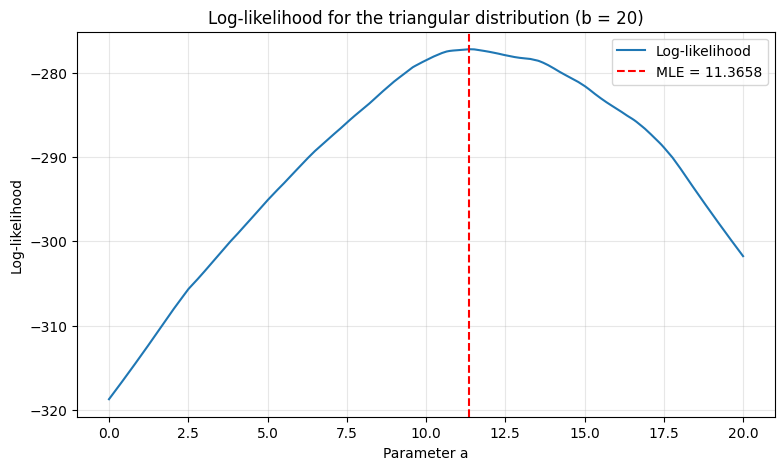

In [52]:
# TODO: answer Question 5, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 
b = 20
eps = 1e-8
a_min = eps * b
a_max = (1 - eps) * b

sample = np.asarray(data, dtype=float)


def log_likelihood(a, x, b=20):
    if not (0 < a < b):
        return -np.inf

    x = np.asarray(x)

    # Log-density for each observation
    log_pdf = np.where(
        x <= a,
        np.log(2 / b) + np.log(x / a),
        np.log(2 / b) + np.log((b - x) / (b - a))
    )

    return np.sum(log_pdf)


# 1. Evaluate the log-likelihood on a dense grid
grid = np.linspace(a_min, a_max, 100_001)
ll_grid = np.array([
    log_likelihood(a, sample, b) for a in grid
])

a_grid = grid[np.argmax(ll_grid)]
ll_grid_max = np.max(ll_grid)

# 2. Also evaluate it at the sample locations
sample_candidates = sample[
    (sample >= a_min) & (sample <= a_max)
]

candidates = np.unique(np.concatenate([
    [a_min, a_max],
    sample_candidates,
    [a_grid]
]))

ll_candidates = np.array([
    log_likelihood(a, sample, b) for a in candidates
])

best_idx = np.argmax(ll_candidates)
a_mle = candidates[best_idx]
ll_max = ll_candidates[best_idx]

# 3. Check whether the solution reaches a numerical boundary
boundary_tol = 1e-12 * b
at_boundary = (
    abs(a_mle - a_min) <= boundary_tol
    or abs(a_mle - a_max) <= boundary_tol
)

print(f"Grid estimate: {a_grid:.10f}")
print(f"Maximum likelihood estimate (MLE): {a_mle:.10f}")
print(f"Maximum log-likelihood: {ll_max:.6f}")
print(f"Numerical boundary reached: {at_boundary}")

# 4. Plot
plt.figure(figsize=(9, 5))
plt.plot(grid, ll_grid, label="Log-likelihood")
plt.axvline(
    a_mle, color="red", linestyle="--",
    label=f"MLE = {a_mle:.4f}"
)
plt.xlabel("Parameter a")
plt.ylabel("Log-likelihood")
plt.title("Log-likelihood for the triangular distribution (b = 20)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#### Results and Interpretation

We plot the log-likelihood as a function of $a$ and search for its maximum using a dense grid and the sample locations, rather than relying on a single local optimizer. 

For $b=20$, the maximum likelihood estimate is

$$
\hat{a}_{\mathrm{MLE}} \approx 11.3658.
$$

The corresponding maximum log-likelihood is

$$
\ell(\hat{a}_{\mathrm{MLE}}) \approx -277.1913.
$$

The numerical boundary check returns `False`. Therefore, the estimated maximum does not reach either endpoint of the optimization interval.


#### Multiple local maxima

The log-likelihood can have several local maxima because its expression changes whenever $a$ crosses an observation $x_i$. Between consecutive observations, it is convex, since

$$
\ell''(a)=\frac{k}{a^2}+\frac{n-k}{(b-a)^2}\geq0,
$$

where $k$ is the number of observations satisfying $x_i\leq a$.

Therefore, local maxima can occur at sample locations or at the numerical boundaries. We check a dense grid and the sample locations to identify the global maximum rather than relying on a single local optimizer.

### Question 6 — Bootstrap uncertainty

Use 1,000 nonparametric bootstrap samples of size $n$ to compute percentile 95%
confidence intervals for the mean, median, and maximum-likelihood estimators.
Use the same bootstrap samples for the three estimators. Report the point estimates
and intervals. Explain the frequentist interpretation and whether a unique
integer value of $a$ is established.

In [53]:
# TODO: answer Question 6, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

B = 1000
b = 20
eps = 1e-8

sample = np.asarray(data, dtype=float)
n = len(sample)

rng = np.random.default_rng(SEED)


def estimate_mle(x, b):
    lower = eps * b
    upper = (1 - eps) * b

    # The maximum can occur at a sample location or a boundary
    candidates = np.unique(np.concatenate((
        [lower, upper],
        x[(x >= lower) & (x <= upper)]
    )))

    A = candidates[:, None]
    X = x[None, :]

    log_pdf = np.where(
        X <= A,
        np.log(2 / b) + np.log(X / A),
        np.log(2 / b) + np.log((b - X) / (b - A))
    )

    log_likelihood = np.sum(log_pdf, axis=1)
    return candidates[np.argmax(log_likelihood)]

# Point estimates
point_mean = estimate_a_mean(sample, b)
point_median = estimate_a_median(sample, b)
point_mle = estimate_mle(sample, b)

# Bootstrap: use the same resampled data for all estimators
bootstrap_estimates = np.empty((B, 3))

for j in range(B):
    boot_sample = rng.choice(sample, size=n, replace=True)

    bootstrap_estimates[j, 0] = estimate_a_mean(boot_sample, b)
    bootstrap_estimates[j, 1] = estimate_a_median(boot_sample, b)
    bootstrap_estimates[j, 2] = estimate_mle(boot_sample, b)

# Percentile 95% confidence intervals
lower_ci = np.percentile(bootstrap_estimates, 2.5, axis=0)
upper_ci = np.percentile(bootstrap_estimates, 97.5, axis=0)

names = ["Mean", "Median", "MLE"]
point_estimates = [point_mean, point_median, point_mle]

print(f"Sample size: n = {n}")
print(f"Number of bootstrap samples: {B}\n")

for i, name in enumerate(names):
    print(
        f"{name:8s}: estimate = {point_estimates[i]:.4f}, "
        f"95% CI = [{lower_ci[i]:.4f}, {upper_ci[i]:.4f}]"
    )

Sample size: n = 100
Number of bootstrap samples: 1000

Mean    : estimate = 12.2193, 95% CI = [9.8543, 14.6368]
Median  : estimate = 11.4501, 95% CI = [9.9208, 13.2938]
MLE     : estimate = 11.3658, 95% CI = [9.8570, 13.9666]


#### Frequentist Interpretation

A 95% bootstrap confidence interval gives a range of plausible values for the unknown parameter $a$, based on the observed sample. It is constructed by repeatedly resampling the data and recalculating the estimator. A 95% confidence interval means that, over many repeated samples, approximately 95% of the confidence intervals constructed using this method would contain the true value of $a$. It does not mean that the fixed parameter has a 95% probability of belonging to the particular interval obtained from the data.

#### Is a unique integer value established ?

To determine whether the data support a unique integer value for $a$, we examine the integers contained in the confidence interval. The mean-based interval contains the integers 10, 11, 12, 13 and 14, while the median-based and MLE intervals each contain 10, 11, 12 and 13. Therefore, none of the three confidence intervals identifies a unique integer value for $a$.

Even if a confidence interval contained only one integer, this would not prove that the true parameter equals that integer.

### Question 7 — Fisher information and the Cramér–Rao bound

Compute the one-observation Fisher information
$I_1(a)=\mathbb E[(\partial_a\log p(X;a,b))^2]$ for fixed $b$ and interior $a$.
Deduce $I_n(a)$ and the Cramér–Rao variance bound for an unbiased estimator.
Which of the estimators above is known to be unbiased? Explain why the unbiased
bound must not be asserted as a finite-sample MSE bound for every estimator.

In [9]:
# TODO: answer Question 7, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

#### 1. Fisher information for one-observation

For the triangular distribution with known $b$ and unknown $a\in(0,b)$, the probability density function is

$$
p(x;a,b)=
\begin{cases}
\dfrac{2x}{ab} & 0\leq x\leq a\\[6pt]
\dfrac{2(b-x)}{b(b-a)} & a<x\leq b\\[6pt]
0 & \text{otherwise}
\end{cases}
$$

The score function is

$$
S_a(x)=\frac{\partial}{\partial a}\log p(x;a,b)
=
\frac{\partial}{\partial a}
\begin{cases}
log(2/b)+log(x)-log(a), &0\leq x \leq a\\
log(2/b)+log(b-x)-log(b-a), &a\leq x \leq b\\
\end{cases}
=
\begin{cases}
-\dfrac{1}{a}, & x<a\\[6pt]
undefined, & x=a\\[6pt]
\dfrac{1}{b-a}, & x>a
\end{cases}
$$

Fisher information for one observation is
$$
I_1(a) = \mathbb E[(\partial_a\log p(X;a,b))^2] = \int_0^a \left(-\frac{1}{a}\right)^2 p(x;a,b)dx + \int_a^b\left(\frac{1}{b-a}\right)^2p(x;a,b)dx
= \int_0^a \left(-\frac{1}{a}\right)^2 \frac{2}{b}\frac{x}{a}dx + \int_a^b\left(\frac{1}{b-a}\right)^2\frac{2}{b}\frac{b-x}{b-a}dx$$
$$= \left(-\frac{1}{a}\right)^2 \frac{2}{b}\int_0^a\frac{x}{a}dx + \left(\frac{1}{b-a}\right)^2\frac{2}{b}\frac{1}{b-a}\int_a^b(b-x)dx
= \left(-\frac{1}{a}\right)^2 \frac{2}{b}\frac{a}{2} + \left(\frac{1}{b-a}\right)^2\frac{2}{b}\frac{1}{b-a}\left(\frac{b^2}{2} - ab + \frac{a^2}{2}\right)$$
$$= \frac{1}{a^2} \frac{a}{b} + \frac{1}{(b-a)^3}\frac{1}{b}\left(b^2 - 2ab + a^2\right) 
= \frac{1}{ab} + \frac{1}{b(b-a)} 
= \frac{b-a+a}{ab(b-a)} 
= \frac{1}{a(b-a)}
$$


$$
\Rightarrow I_1(a)=\mathbb{E}[S_a(X)^2]=\boxed{\frac{1}{a(b-a)}}
$$

#### 2. Fisher information for $n$ observations

For an sample of $n$ independent and identically distributed observations, Fisher information is additive :

$$
\boxed{I_n(a)=nI_1(a)=\frac{n}{a(b-a)}}
$$

#### 3. Cramér–Rao variance bound for an unbiased estimator

For any unbiased estimator $\hat{a}$, the Cramér–Rao inequality gives

$$
\operatorname{Var}(\hat{a})
\geq \frac{1}{I_n(a)}
$$

Therefore,

$$
\boxed{\operatorname{Var}(\hat{a})\geq\frac{a(b-a)}{n}}
$$

#### 4. Unbiased estimators

The mean-based estimator is unbiased because

$$
\begin{aligned}
\mathbb{E}[\hat{a}_{\mathrm{mean}}]
&=\mathbb{E}[3\bar{X}-b]\\
&=3\mathbb{E}[\bar{X}]-b\\
&=3\frac{a+b}{3}-b\\
&=a
\end{aligned}
$$

Thus,

$$
\mathbb{E}[\hat{a}_{\mathrm{mean}}]=a
\Rightarrow\boxed{Bias(\hat a_{\mathrm{mean}}) = \mathbb E[\hat a_{\mathrm{mean}}] - a = 0}
$$

The median-based and maximum likelihood estimators are not generally known to be unbiased in finite samples.

#### 5. Why the unbiased bound is not a universal finite-sample MSE bound ?

The Cramér–Rao lower bound states that

$$
\operatorname{Var}(\hat{a})
\geq \frac{a(b-a)}{n}
$$

for unbiased estimators.

However, this inequality does not automatically apply to biased estimators. The mean squared error satisfies

$$
\operatorname{MSE}(\hat{a})
=
\operatorname{Var}(\hat{a})
+
\operatorname{Bias}(\hat{a})^2
$$

where

$$
\operatorname{Bias}(\hat{a})
=
\mathbb{E}[\hat{a}]-a
$$

For an unbiased estimator, the bias is zero, so its MSE equals its variance. For a biased estimator, however, the MSE depends on both its variance and its squared bias. Consequently, a biased estimator may have a variance below the Cramér–Rao bound, and its MSE may also be below that bound if its squared bias is sufficiently small.

Therefore, Cramér–Rao bound cannot be used as a universal finite-sample lower bound for the MSE of every estimator.

### Question 8 — Jeffreys prior and posterior estimation

Derive and normalize Jeffreys prior $\pi_J(a)\propto\sqrt{I_1(a)}$ on $(0,b)$.
Inspect the posterior density near the boundaries: does maximizing it define a
finite interior global MAP estimate? Distinguish MAP from maximum likelihood.

Instead, compute the posterior mean and an equal-tailed 95% credible interval
for `fixed_b.npy`. Numerical integration is sufficient. Hint: the substitution
$a=b\sin^2\theta$, $0<\theta<\pi/2$, removes the prior's integrable endpoint
singularities. Compare the interpretation with Question 6. Check numerical
stability by increasing your integration resolution.

#### 1. Jeffreys Prior

The Fisher information for one observation is

$$
I_1(a)=\frac{1}{a(b-a)}, \qquad 0<a<b
$$

Jeffreys prior is defined as

$$
\pi_J(a)\propto\sqrt{I_1(a)}
=\frac{1}{\sqrt{a(b-a)}}
$$

To normalize this prior, we search a constant C such that

$$
\int_0^b\frac{C}{\sqrt{a(b-a)}}da=1
$$

To do that, we use the substitution

$$
a=b\sin^2\theta,
\qquad 0<\theta<\frac{\pi}{2}
$$

Since

$$
da=2b\sin\theta\cos\theta\,d\theta,
$$

we obtain

$$
\int_0^b\frac{C}{\sqrt{a(b-a)}}\,da
=C\int_0^{\pi/2}2\,d\theta
=C\pi
$$

Therefore, $C=1/\pi$ and the normalized Jeffreys prior is

$$
\boxed{
\pi_J(a)=\frac{1}{\pi\sqrt{a(b-a)}}
\qquad 0<a<b
}
$$

Although this density diverges at both endpoints, its singularities are integrable, so the prior is proper.

#### 2. Posterior density and MAP estimate

By Bayes' theorem, the posterior density is

$$
p(a\mid x_1,\ldots,x_n)
=
\frac{L(a)\pi_J(a)}
{\displaystyle\int_0^b L(u)\pi_J(u)\,du}
$$

For observations strictly between $0$ and $b$, the likelihood approaches a finite, positive limit as $a$ approaches either endpoint. However, Jeffreys prior diverges at both endpoints, since its denominator will go to zero. Consequently,

$$
\lim_{a\to0^+}p(a\mid x)=+\infty
\qquad
\lim_{a\to b^-}p(a\mid x)=+\infty
$$

Thus, the posterior density is unbounded near the boundaries and does not reach a finite global maximum inside this interval. Therefore, a global interior MAP estimate is not defined.

The maximum likelihood estimator (MLE) maximizes the likelihood $L(a)$, whereas the maximum a posteriori (MAP) estimator maximizes the posterior density $L(a)\pi_J(a)$, up to a normalization constant. 

#### 3. Posterior Mean and 95% Credible Interval

In [58]:
# TODO: answer Question 8, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 
import numpy as np
from scipy.integrate import cumulative_trapezoid

# Load the sample
sample = np.asarray(np.load("fixed_b.npy"), dtype=float).ravel()
b = 20.0

# Log-likelihood for the standard triangular distribution
def log_likelihood(a, sample, b):
    if not 0 < a < b:
        return -np.inf

    left = sample <= a
    result = np.empty_like(sample)

    result[left] = (
        np.log(2 / b)
        + np.log(sample[left] / a)
    )

    result[~left] = (
        np.log(2 / b)
        + np.log((b - sample[~left]) / (b - a))
    )

    return np.sum(result)


def posterior_estimates(sample, b, N):
    
    theta = np.linspace(0, np.pi / 2, N + 1)
    a = b * np.sin(theta)**2

    # Avoid evaluating the likelihood exactly at the boundaries
    a_safe = np.clip(a, 1e-12 * b, (1 - 1e-12) * b)

    logL = np.array([
        log_likelihood(ai, sample, b) for ai in a_safe
    ])

    # Stabilize exponentiation
    likelihood = np.exp(logL - np.max(logL))

    # Posterior density in theta is proportional to likelihood
    normalizer = np.trapezoid(likelihood, theta)
    density_theta = likelihood / normalizer

    # Transform back to obtain the posterior mean of a
    posterior_mean = np.trapezoid(
    a * density_theta, theta
    )

    # CDF in theta
    cdf = cumulative_trapezoid(
        density_theta, theta, initial=0
    )
    cdf /= cdf[-1]

    # Equal-tailed 95% credible interval
    theta_low = np.interp(0.025, cdf, theta)
    theta_high = np.interp(0.975, cdf, theta)

    a_low = b * np.sin(theta_low)**2
    a_high = b * np.sin(theta_high)**2

    return posterior_mean, a_low, a_high


# Check numerical stability at increasing resolutions
for N in [10, 100, 10000, 100000]:
    mean_a, ci_low, ci_high = posterior_estimates(
        sample, b, N
    )

    print(
        f"N = {N:>6}: "
        f"Posterior mean = {mean_a:.6f}, "
        f"95% credible interval = "
        f"[{ci_low:.6f}, {ci_high:.6f}]"
    )

N =     10: Posterior mean = 11.725704, 95% credible interval = [7.248491, 15.656213]
N =    100: Posterior mean = 11.649322, 95% credible interval = [9.715869, 13.965792]
N =  10000: Posterior mean = 11.649499, 95% credible interval = [9.740934, 13.947719]
N = 100000: Posterior mean = 11.649499, 95% credible interval = [9.740938, 13.947716]


The interval converges to [9.74, 13.94] as we increase the number of integration steps.

#### 4. Comparison with question 6

In Question 6, the bootstrap confidence interval is based on repeated resampling of the data. It has a frequentist interpretation : if we repeated the sampling process many times, approximately 95% of the intervals would contain the true parameter.

In Question 8, the Bayesian credible interval has a different meaning. Given the observed data and the chosen prior, there is a 95% probability that the true parameter lies within the calculated interval.

Therefore, both intervals describe uncertainty about the parameter, but they do it in different ways. 

### Question 9 — Sampling the distribution

Derive an inverse-CDF sampler from Question 2. Implement a vectorized function
`sample_triangular(a, b, size, rng)`, and check its empirical mean and histogram
using 10,000 samples with $a=13,b=20$. Explain why it avoids the repeated rejection
steps of a rejection sampler. Use only interior parameters $0<a<b$.

#### 1. Inverse-CDF sampling

The cumulative distribution function (CDF) of the triangular distribution with parameters $0<a<b$ is

$$
F(x)=
\begin{cases}
0 & x<0\\[4pt]
\dfrac{x^2}{ab} & 0\leq x\leq a\\[8pt]
1-\dfrac{(b-x)^2}{b(b-a)} & a<x\leq b\\[8pt]
1 & x>b
\end{cases}
$$

To generate random samples, let $U\sim\mathcal U(0,1)$. The inverse-CDF method sets $X=F^{-1}(U)$.

The CDF at the mode $a$ is

$$
F(a)=\frac{a}{b}
$$

Therefore, if $U\leq a/b$ $\rightarrow$ $t\leq a$ :

$$
U=\frac{X^2}{ab}
\quad\Longrightarrow\quad
X=\sqrt{abU}
$$

Otherwise,

$$
U=1-\frac{(b-X)^2}{b(b-a)}
\quad\Longrightarrow\quad
X=b-\sqrt{b(b-a)(1-U)}
$$

Thus, the inverse-CDF sampler is

$$
\boxed{
X=
\begin{cases}
\sqrt{abU} & U\leq a/b\\[5pt]
b-\sqrt{b(b-a)(1-U)} & U>a/b
\end{cases}
}
$$

Empirical mean:  10.9636
Theoretical mean: 11.0000


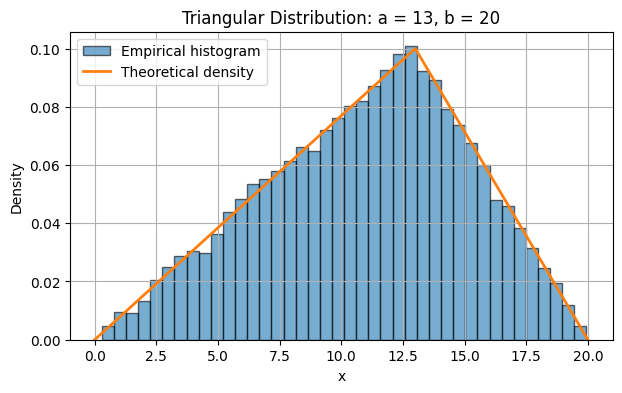

In [11]:
# TODO: answer Question 9, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

def sample_triangular(a, b, size, rng):
    if not (0 < a < b):
        raise ValueError("Parameters must satisfy 0 < a < b.")

    u = rng.uniform(0, 1, size=size)

    x = np.where(
        u <= a / b,
        np.sqrt(a * b * u),
        b - np.sqrt(b * (b - a) * (1 - u))
    )

    return x


# Generate 10,000 observations
a = 13
b = 20
n = 10_000
rng = np.random.default_rng(42)

sample = sample_triangular(a, b, n, rng)

# Compare empirical and theoretical means
empirical_mean = np.mean(sample)
theoretical_mean = (a + b) / 3

print(f"Empirical mean:  {empirical_mean:.4f}")
print(f"Theoretical mean: {theoretical_mean:.4f}")

# Plot empirical histogram and theoretical density
x = np.linspace(0, b, 500)

density = np.where(
    x <= a,
    2 * x / (a * b),
    2 * (b - x) / (b * (b - a))
)

plt.hist(
    sample,
    bins=40,
    density=True,
    alpha=0.6,
    edgecolor="black",
    label="Empirical histogram"
)
plt.plot(x, density, linewidth=2, label="Theoretical density")

plt.xlabel("x")
plt.ylabel("Density")
plt.title("Triangular Distribution: a = 13, b = 20")
plt.legend()
plt.show()

#### 2. Theoretical validation

We generate 10,000 observations with $a=13$ and $b=20$, then compare their empirical mean and histogram with the theoretical distribution.

The theoretical mean is

$$
\mathbb E[X]=\frac{a+b}{3}
=\frac{13+20}{3}=11
$$

The histogram should approximate the triangular density, increasing linearly up to $a=13$ and decreasing linearly from $a=13$ to $b=20$. 

Looking at the graph, it represents exactly what was expected. The empirical mean is $10.96 \approx 11$ and the triangular peak is at $13$.

#### 3. Why it avoids the repeated rejection steps of a rejection sampler ?

Inverse-CDF sampling transforms each uniform random variable into a valid observation using the inverse CDF. Every generated value is valid in $[0,b]$, so no samples need to be rejected. In contrast, rejection sampling may require several attempts to obtain one accepted observation. This is a waste of computational cycles, as it computes points that will be rejected. Therefore, inverse-CDF sampling is often more efficient when the inverse CDF is easy to compute.

### Question 10 — Compare the estimators in repeated experiments

Set $b=20$ and $n=1000$. For ten values of $a$ evenly spaced between 1 and 19,
repeat the experiment 300 times. On each sample compute the mean, median, MLE,
and Jeffreys posterior-mean estimates. Reuse the same sample for all estimators.
Plot estimated MSE with Monte Carlo standard errors, together with the unbiased
Cramér–Rao reference. Which estimators perform well, and does the answer depend
on $a$? Do not interpret a small Monte Carlo difference as a universal ranking.
For the posterior mean, 801 quadrature points are sufficient for this experiment;
check selected cases at higher resolution.

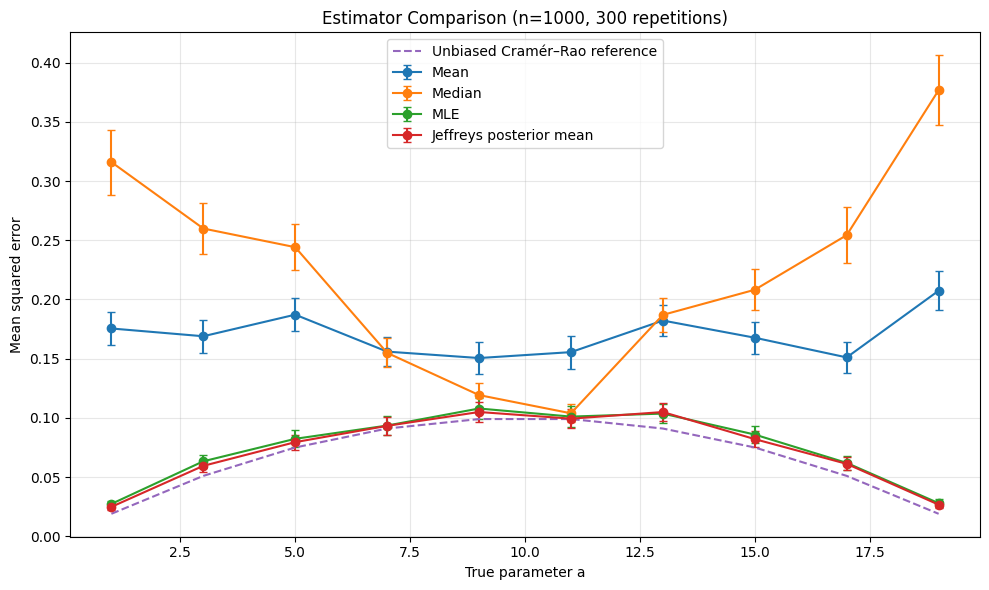


MONTE CARLO MSE RESULTS
Parameters: b = 20.0, sample size n = 1000, repetitions R = 300

  True a |                  Mean |                Median |                   MLE |   Jeffreys posterior mean
------------------------------------------------------------------------------------------------------------
     1.0 |  0.175484 ± 0.013855 |  0.315985 ± 0.027512 |  0.027337 ± 0.002478 |  0.024850 ± 0.002253 | 
     3.0 |  0.168923 ± 0.014019 |  0.259893 ± 0.021629 |  0.063333 ± 0.005683 |  0.059497 ± 0.005325 | 
     5.0 |  0.187153 ± 0.014155 |  0.244120 ± 0.019559 |  0.082318 ± 0.007119 |  0.079493 ± 0.006405 | 
     7.0 |  0.155941 ± 0.012380 |  0.154897 ± 0.012213 |  0.093504 ± 0.007895 |  0.093283 ± 0.007772 | 
     9.0 |  0.150528 ± 0.013305 |  0.119238 ± 0.009948 |  0.107907 ± 0.009036 |  0.104956 ± 0.008756 | 
    11.0 |  0.155512 ± 0.014035 |  0.103854 ± 0.007701 |  0.101077 ± 0.008621 |  0.099342 ± 0.008137 | 
    13.0 |  0.182184 ± 0.013470 |  0.186971 ± 0.014530 |  0.103619 ±

In [62]:
# TODO: answer Question 10, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

# Parameters
b = 20.0
n = 1000
R = 300
a_values = np.linspace(1, 19, 10)
rng = np.random.default_rng(SEED)


# 1. Inverse-CDF sampling
def sample_triangular(a, b, size, rng):
    if not (0 < a < b):
        raise ValueError("Require 0 < a < b.")

    u = rng.uniform(size=size)
    return np.where(
        u <= a / b,
        np.sqrt(a * b * u),
        b - np.sqrt(b * (b - a) * (1 - u))
    )


# 2. Mean and median estimators
def estimate_mean(x, b):
    return 3 * np.mean(x) - b


def estimate_median(x, b):
    m = np.median(x)
    if m >= b / 2:
        return 2 * m**2 / b
    return b - 2 * (b - m)**2 / b


# 3. Log-likelihood for multiple candidate values of a
def loglikelihood_candidates(candidates, x, b):
    x_sorted = np.sort(x)
    log_x = np.log(x_sorted)
    log_bx = np.log(b - x_sorted)

    # Prefix sums and suffix sums
    prefix = np.concatenate(([0.0], np.cumsum(log_x)))
    suffix = np.concatenate((np.cumsum(log_bx[::-1])[::-1], [0.0]))

    k = np.searchsorted(x_sorted, candidates, side="right")
    k = np.clip(k, 0, len(x_sorted))

    return (
        len(x) * np.log(2 / b)
        + prefix[k]
        - k * np.log(candidates)
        + suffix[k]
        - (len(x) - k) * np.log(b - candidates)
    )


def estimate_mle(x, b):
    eps = 1e-10
    candidates = np.unique(np.concatenate((
        [eps * b, (1 - eps) * b],
        x[(x > eps * b) & (x < (1 - eps) * b)]
    )))
    logL = loglikelihood_candidates(candidates, x, b)
    return candidates[np.argmax(logL)]


# 4. Jeffreys posterior mean by midpoint quadrature in theta
def posterior_mean_jeffreys(x, b, N=801):
    theta = (np.arange(N) + 0.5) * (np.pi / 2 / N)
    a_grid = b * np.sin(theta)**2

    logL = loglikelihood_candidates(a_grid, x, b)

    # Stabilize exponentiation
    weights = np.exp(logL - np.max(logL))

    # The transformed Jeffreys prior is constant in theta,
    # so it cancels in the ratio defining the posterior mean.
    return np.sum(a_grid * weights) / np.sum(weights)


# 5. Repeated experiments
estimator_names = ["Mean", "Median", "MLE", "Jeffreys posterior mean"]
squared_errors = np.zeros((len(a_values), R, 4))

for i, a_true in enumerate(a_values):
    for r in range(R):
        # Reuse the same sample for all estimators
        x = sample_triangular(a_true, b, n, rng)

        estimates = [
            estimate_mean(x, b),
            estimate_median(x, b),
            estimate_mle(x, b),
            posterior_mean_jeffreys(x, b, N=801)
        ]

        squared_errors[i, r, :] = (
            np.asarray(estimates) - a_true
        )**2


# Monte Carlo MSE and its standard error
mse = np.mean(squared_errors, axis=1)
mc_se = np.std(squared_errors, axis=1, ddof=1) / np.sqrt(R)

crlb = a_values * (b - a_values) / n


# 6. Plot
plt.figure(figsize=(10, 6))

for j, name in enumerate(estimator_names):
    plt.errorbar(
        a_values, mse[:, j],
        yerr=mc_se[:, j],
        marker="o", capsize=3,
        label=name
    )

plt.plot(
    a_values, crlb, "--",
    label="Unbiased Cramér–Rao reference"
)

plt.xlabel("True parameter a")
plt.ylabel("Mean squared error")
plt.title("Estimator Comparison (n=1000, 300 repetitions)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 7. Display numerical results

print("\n" + "=" * 95)
print("MONTE CARLO MSE RESULTS")
print("=" * 95)
print(f"Parameters: b = {b}, sample size n = {n}, repetitions R = {R}\n")

header = (
    f"{'True a':>8} | "
    f"{'Mean':>21} | "
    f"{'Median':>21} | "
    f"{'MLE':>21} | "
    f"{'Jeffreys posterior mean':>25}"
)

print(header)
print("-" * len(header))

for i, a_true in enumerate(a_values):
    row = f"{a_true:8.1f} | "

    for j in range(4):
        row += f"{mse[i, j]:9.6f} ± {mc_se[i, j]:.6f} | "

    print(row)

print("\n" + "=" * 50)
print("CRAMÉR–RAO REFERENCE")
print("=" * 50)
print(f"{'True a':>10} | {'CRLB':>12}")
print("-" * 26)

for a_true, bound in zip(a_values, crlb):
    print(f"{a_true:10.1f} | {bound:12.6f}")


# 8. Check numerical stability of the posterior quadrature grid
print("\n" + "=" * 75)
print("POSTERIOR MEAN : QUADRATURE GRID STABILITY")
print("=" * 75)

grid_sizes = [801, 1601, 3201]

print(f"{'True a':>8} | {'Grid 801':>14} | {'Grid 1601':>14} | "
      f"{'Grid 3201':>14} | {'Max difference':>16}")
print("-" * 82)

for a_true in [1.0, 10.0, 19.0]:

    # Generate one sample and reuse it for every grid resolution
    x = sample_triangular(a_true, b, n, rng)

    results = [
        posterior_mean_jeffreys(x, b, N)
        for N in grid_sizes
    ]

    max_difference = max(results) - min(results)

    print(
        f"{a_true:8.1f} | "
        f"{results[0]:14.6f} | "
        f"{results[1]:14.6f} | "
        f"{results[2]:14.6f} | "
        f"{max_difference:16.8f}"
    )

#### Results and interpretation

The mean and median give the largest MSE values. Their results are far from the Cramér–Rao lower bound, especially when $a$ is far from the centre. The median gives better results when $a=9$ or $a=11$.

The MLE and Jeffreys estimators have similar results. They give the best results. Their MSE values are very close to the Cramér–Rao lower bound and are much smaller than those of the mean and median, especially near the edges of the interval.

#### Grid resolution impact
The MSE values are almost the same for all three grid sizes. The differences are very small, even when comparing 801 and 3201 points. This shows that a grid of 801 points is already accurate enough for our experiment.

Alex has changed the code. In the next questions, `full.npy` contains a new sample
with both $a$ and $b$ unknown. Neither parameter need equal the earlier value.
Continue treating parameters as continuous before discussing the integer code.

### Question 11 — Joint maximum-likelihood estimation

Load `full.npy`, report its size, and plot a density histogram. Estimate both
parameters by maximizing the likelihood under $0<a<b\le99$ and $b>\max_i x_i$.
Check numerical feasibility and compare several candidate values or starts.
Hint: for each fixed $b$, reuse the candidate-location method from Question 5,
then numerically maximize the resulting profile likelihood over $b$.

Sample size: n = 10000
Minimum observation: 0.531621
Maximum observation: 77.500095
MLE: a_hat = 41.5952, b_hat = 77.9189
Maximum log-likelihood: -41648.5041


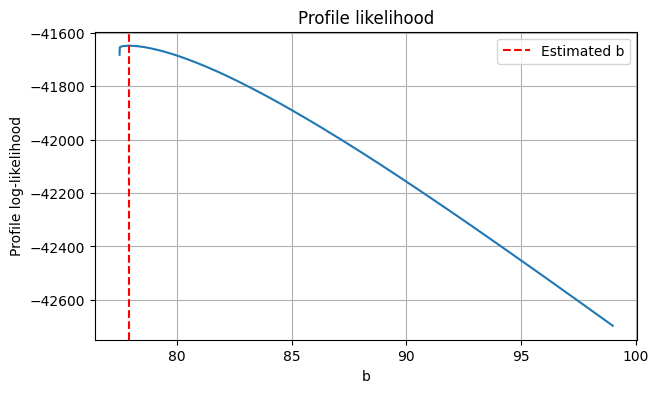

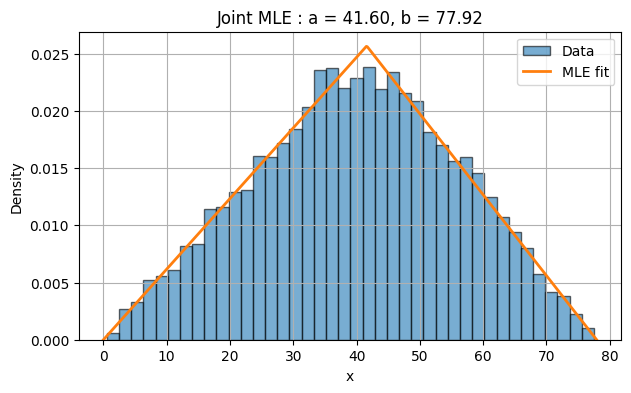

In [ ]:
# TODO: answer Question 11, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

# Load the data
data_full = np.load("full.npy")
n = len(data_full)
x_sorted_full = np.sort(data_full)

print(f"Sample size: n = {n}")
print(f"Minimum observation: {x_sorted_full[0]:.6f}")
print(f"Maximum observation: {x_sorted_full[-1]:.6f}")


def profile_ll(xs, b):
    if b <= xs[-1] or b > 99:
        return -np.inf, np.nan

    n = len(xs)
    candidates = np.unique(xs[(xs > 0) & (xs < b)])
    candidates = np.unique(np.concatenate((candidates, b * np.arange(1, n) / n)))

    k = np.searchsorted(xs, candidates, side="right")
    cum_log_x = np.concatenate(([0.0], np.cumsum(np.log(xs))))
    suffix_log_bx = np.concatenate(
        (np.cumsum(np.log(b - xs)[::-1])[::-1], [0.0])
    )

    values = (
        n * np.log(2 / b)
        + cum_log_x[k]
        + suffix_log_bx[k]
        - k * np.log(candidates)
        - (n - k) * np.log(b - candidates)
    )

    j = np.argmax(values)
    return values[j], candidates[j]


def fit_joint(xs, b_max=99.0, n_coarse=2000, n_fine=400):
    b_min = np.nextafter(xs[-1], np.inf)
    b_grid = np.linspace(b_min, b_max, n_coarse)

    profile_values = np.array([profile_ll(xs, b)[0] for b in b_grid])
    j = np.argmax(profile_values)

    b_fine = np.linspace(
        b_grid[max(j - 1, 0)],
        b_grid[min(j + 1, n_coarse - 1)],
        n_fine
    )

    fine_values = np.array([profile_ll(xs, b)[0] for b in b_fine])
    j_fine = np.argmax(fine_values)

    b_hat = b_fine[j_fine]
    ll_hat, a_hat = profile_ll(xs, b_hat)

    return a_hat, b_hat, ll_hat, b_grid, profile_values


# Estimate both parameters
a_hat, b_hat, ll_hat, b_grid, profile_values = fit_joint(x_sorted_full)

print(f"MLE: a_hat = {a_hat:.4f}, b_hat = {b_hat:.4f}")
print(f"Maximum log-likelihood: {ll_hat:.4f}")


# Plot profile likelihood
plt.plot(b_grid, profile_values)
plt.axvline(b_hat, color="red", linestyle="--", label="Estimated b")
plt.xlabel("b")
plt.ylabel("Profile log-likelihood")
plt.title("Profile likelihood")
plt.legend()
plt.show()


# Plot empirical histogram and fitted density
x = np.linspace(0, b_hat, 500)

density = np.where(
    x <= a_hat,
    2 * x / (a_hat * b_hat),
    2 * (b_hat - x) / (b_hat * (b_hat - a_hat))
)

plt.hist(data_full, bins=40, density=True, alpha=0.6,
         edgecolor="black", label="Data")
plt.plot(x, density, linewidth=2, label="MLE fit (a = {a_hat:.2f}, b = {b_hat:.2f})")

plt.xlabel("x")
plt.ylabel("Density")
plt.title(f"Joint MLE")
plt.legend()
plt.show()

#### Results and interpretation

The first plot shows that the maximum of the profile log-likelihood is reached around $\hat{b}=77.9189$.

The second plot shows an accurante fit. The resulting maximum likelihood estimates are :

$
\hat{a}=41.5952,\qquad \hat{b}=77.9189
$

The maximum log-likelihood is \(-41648.5041\).

The estimates satisfy all the constraints : $0 < \hat{a} < \hat{b} \leq 99$, and $\hat{b}$ is greater than the maximum observation (77.5). 

### Question 12 — Joint uncertainty and the code

Use 300 nonparametric bootstrap replicates to obtain marginal percentile 95%
intervals for $a$ and $b$ (you may increase this number). Display the bootstrap
estimates together in a scatter plot. Give a plausible integer code, list the
integer pairs inside the two marginal intervals, and explain why these intervals
do not guarantee unique or joint 95% recovery. Discuss the additional caution
needed when a parameter controls the support of a distribution.

95% percentile intervals
a: [40.55, 42.25]
b: [77.62, 78.23]
Integer pairs inside the intervals
[(41, 78), (42, 78)]


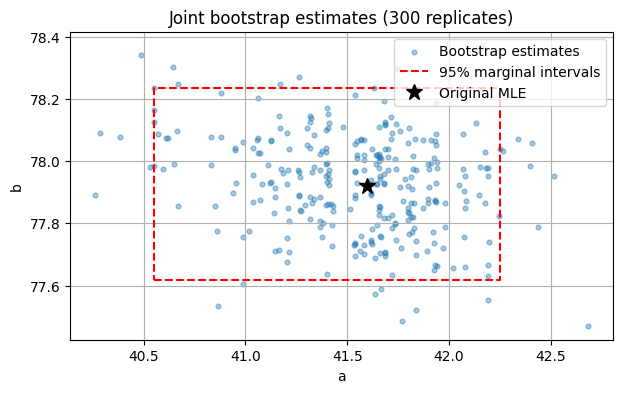

In [ ]:
# TODO: answer Question 12, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer:

# Nonparametric bootstrap
nbr_bootstrap = 300
rng = np.random.default_rng(SEED)
boot = np.empty((nbr_bootstrap, 2))

for i in range(nbr_bootstrap):
    xb = np.sort(rng.choice(data_full, size=n, replace=True))
    a_b, b_b, _, _, _ = fit_joint(xb, n_coarse=300, n_fine=200)
    boot[i] = a_b, b_b


# 95% marginal percentile intervals
a_lo, a_up = np.percentile(boot[:, 0], [2.5, 97.5])
b_lo, b_up = np.percentile(boot[:, 1], [2.5, 97.5])

print("95% percentile intervals")
print(f"a: [{a_lo:.2f}, {a_up:.2f}]")
print(f"b: [{b_lo:.2f}, {b_up:.2f}]")


# Integer pairs inside the intervals
a_ints = range(int(np.ceil(a_lo)), int(np.floor(a_up)) + 1)
b_ints = range(int(np.ceil(b_lo)), int(np.floor(b_up)) + 1)

pairs = [(a, b) for a in a_ints for b in b_ints
         if 0 < a < b <= 99 and b > np.max(data_full)]

print("Integer pairs inside the intervals")
print(pairs)


# Plot bootstrap estimates
plt.scatter(boot[:, 0], boot[:, 1], alpha=0.4, s=12,
            label="Bootstrap estimates")

plt.plot([a_lo, a_up, a_up, a_lo, a_lo],
         [b_lo, b_lo, b_up, b_up, b_lo],
         "r--", label="95% marginal intervals")

plt.plot(a_hat, b_hat, "k*", ms=12, label="Original MLE")

plt.xlabel("a_hat")
plt.ylabel("b_hat")
plt.title(f"Joint bootstrap estimates ({nbr_bootstrap} replicates)")
plt.legend()
plt.show()


#### Results and interpretation

The 95% bootstrap confidence intervals are:

$$
a \in [40.55, 42.25], \qquad b \in [77.62, 78.23]
$$

The scatter plot shows the 300 bootstrap estimates of $a$ and $b$. Each point represents one bootstrap sample. The dashed box shows the two confidence intervals : the horizontal limits correspond to $a$, and the vertical limits correspond to $b$.

The integer pairs inside both marginal intervals are $(41, 78)$ and $(42, 78)$.Therefore, the possible codes are $4178$ and $4278$. 

However, these intervals do not guarantee a unique code because they contain two possible integer pairs. They also do not guarantee joint 95% recovery because each parameter is considered separately. The two parameters may be related, so the rectangular box does not fully represent their joint distribution (it can be tilted or elongated). This can be seen in the plot, where the bottom-left corner of the box contains no points. Therefore, we cannot be sure that both parameters are inside their intervals at the same time with 95% confidence.

Finally, we must be careful when interpreting the interval for b. Since each bootstrap sample is drawn from the original data, its maximum value cannot be larger than the original maximum $max(x_i)$. As b controls the upper limit of the distribution, this may lead to an interval that is too narrow. If the original data does not capture the upper tail well, we may underestimate the uncertainty in b.


### Question 13 — Joint moment estimation (optional)

Can the population mean and median identify $(a,b)$? Derive candidate solutions
for both median branches, check the parameter constraints, and try them on
`full.npy`. Explain why finite-sample inversion can be unstable or inadmissible.


### (a,b) identification

The parameters \((a,b)\) can be identified by solving the system of equations for the population mean and median found in previous questions.

Case 1 : $a \geq b/2$

$$
\begin{cases}
\mu = \frac{a+b}{3}\\
m = \sqrt{\frac{ab}{2}}
\end{cases}
$$

From the first equation, we obtain $b=3\mu-a$. Substituting this into the second equation gives,

$$
m = \sqrt{\frac{a(3\mu-a)}{2}}
$$

$$
2m^2 = a(3\mu-a)
$$

$$
a^2-3\mu a+2m^2=0
$$

Solving this quadratic equation gives,

$$
\boxed{a = \frac{3\mu-\sqrt{9\mu^2-8m^2}}{2}}
$$

We then obtain,

$$
\boxed{b=3\mu-a
=\frac{3\mu+\sqrt{9\mu^2-8m^2}}{2}}
$$

For the solution to be real, the discriminant must be non-negative,

$$
\Delta=9\mu^2-8m^2\geq 0
$$

Case 2: $a < b/2$

$$
\begin{cases}
\mu = \frac{a+b}{3}\\
m = b-\sqrt{\frac{b(b-a)}{2}}
\end{cases}
$$

From the first equation, we obtain $a=3\mu-b$. Substituting this into the second equation gives,

$$
m=b-\sqrt{\frac{b(2b-3\mu)}{2}}
$$

Rearranging,

$$
(b-m)^2=\frac{2b^2-3\mu b}{2}
$$

$$
2b^2-4bm+2m^2=2b^2-3\mu b
$$

$$
b(3\mu-4m)=-2m^2
$$

Therefore,

$$
\boxed{b=\frac{2m^2}{4m-3\mu}}
$$

and

$$
\boxed{a=3\mu-b
=3\mu-\frac{2m^2}{4m-3\mu}}
$$

To respect $0<a<b$, the denominator have to be positive,

$$
4m-3\mu>0
$$

**Final constraints**

For both cases, we must check that the estimated parameters satisfy the problem constraints :

$
0<a<b
$
and
$
b>\max(x_i)
$



In [70]:
# TODO: answer Question 13, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

# Empirical mean and median
mu = np.mean(data_full)
m = np.median(data_full)

print(f"Empirical mean: {mu:.6f}")
print(f"Empirical median: {m:.6f}")


candidates = []

# Branch 1: median is below or equal to a
discriminant = 9 * mu**2 - 8 * m**2

if discriminant >= 0:
    for b in [
        (3 * mu + np.sqrt(discriminant)) / 2,
        (3 * mu - np.sqrt(discriminant)) / 2
    ]:
        a = 3 * mu - b
        valid = 0 < a < b <= 99 and m <= a
        candidates.append(("Branch 1", a, b, valid))

# Branch 2: median is above a
denominator = 4 * m - 3 * mu

if denominator > 0:
    b = 2 * m**2 / denominator
    a = 3 * mu - b
    valid = 0 < a < b <= 99 and m > a
    candidates.append(("Branch 2", a, b, valid))


# Display all candidates and check their constraints
print("\nCandidate solutions:")
for branch, a, b, valid in candidates:
    print(
        f"{branch}: a = {a:.6f}, b = {b:.6f}, "
        f"valid = {valid}"
    )

print("\nAdmissible solutions:")
for branch, a, b, valid in candidates:
    if valid:
        print(f"{branch}: (a, b) = ({a:.6f}, {b:.6f})")

Empirical mean: 39.841127
Empirical median: 40.127062

Candidate solutions:
Branch 1: a = 41.024096, b = 78.499285, valid = True
Branch 1: a = 78.499285, b = 41.024096, valid = False
Branch 2: a = 40.948960, b = 78.574421, valid = False

Admissible solutions:
Branch 1: (a, b) = (41.024096, 78.499285)


#### Results and interpretation

Using the empirical mean $\hat{\mu}=39.841127$ and median $\hat{m}=40.127062$, we obtain only one admissible parameter pair :

$$
\boxed{\hat{a}=41.024096 \qquad \hat{b}=78.499285}
$$

The solution from case 1 satisfies all the constraints. The candidate from case 2 is rejected because it does not satisfy the condition $a<b/2$.

This shows that the empirical mean and median identify one admissible parameter pair for this dataset.

However, this inversion can be unstable with finite samples. The sample mean and median are only estimates of their population values. Small changes in these estimates can lead to noticeable changes in the calculated parameters because the equations are nonlinear. They can also produce candidates that do not satisfy the parameter constraints or the conditions of either median branch.

Therefore, even when the population mean and median identify the parameters, their empirical estimates may not always lead to a valid solution.


## Part II — Supervised learning

We now study a separate problem: classifying images of people with and without
a face mask. The aim is to compare simple supervised models and understand how
additional, class-biased data affect learning. This is an educational benchmark,
not a validated deployment system.

The bundled files follow the current 2026 preprocessing rule, with fixed seeds
and exact duplicate images removed before splitting:
- `data/train.npz`: a small labelled sample from the source training partition;
- `data/extra.npz`: additional labelled images, introduced in Question 21;
- `data/test.npz`: a fixed final test partition; leave it unopened until Question 29.

Images are stored as 128×128 RGB arrays in channel-first order `(3, 128, 128)`.
Labels are **0 = with mask**, **1 = without mask**. To make repeated fitting practical,
the provided `image_features` computes fixed 4×4 pixel-block averages, yielding
32×32 RGB images, scaled to [0,1] and flattened to 3,072 features. It learns nothing
from the data. All models and the evaluator use this same representation.

Use an internal training/validation split of `train.npz`. Hyperparameters are
chosen by five-fold cross-validation on the internal training portion. The small
validation set supports development comparisons; it is not the final test set.
Fit scalers only inside training folds. Keep validation and final test observations
out of resampling and fitting. Use **balanced accuracy** as the primary selection
metric and report ordinary accuracy as well. For two classes, balanced accuracy
is the average of the two class recalls. This supports the later imbalance study.

The local final test is accessible, not secret. Evaluate it only after freezing
your choices. Do not claim hidden-test guarantees or select a new model after
seeing final test scores. Model rankings are empirical results, not required answers.

The `search` helper below uses `GridSearchCV` to try different combinations of
hyperparameters and select the one with the best mean cross-validation score
(here, balanced accuracy).

In [14]:
# PROVIDED: data access and deterministic feature representation.
from evaluation import load_file, image_features, scores, evaluate
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             recall_score, confusion_matrix, ConfusionMatrixDisplay)

images, labels = load_file("train")
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy"}

def search(model, grid, X, y):
    # One worker limits peak memory; randomness is set explicitly in estimators.
    return GridSearchCV(model, grid, scoring=SCORING, refit="balanced_accuracy",
                        cv=CV, n_jobs=1, error_score="raise", return_train_score=True).fit(X, y)

### Question 14 — Explore the image dataset

Report the image-array shape, pixel range, and class counts. Plot six labelled
images. Is this small dataset approximately balanced? Explain why label counts
matter when interpreting ordinary accuracy.

Image-array shape (number of images, RGB channels, height (pixels), width (pixels)): (185, 3, 128, 128)
Labels shape: (185,)
Pixel range: 0 to 255
Class 0 (Mask): 99 images
Class 0: 53.5%
Class 1 (No mask): 86 images
Class 1: 46.5%


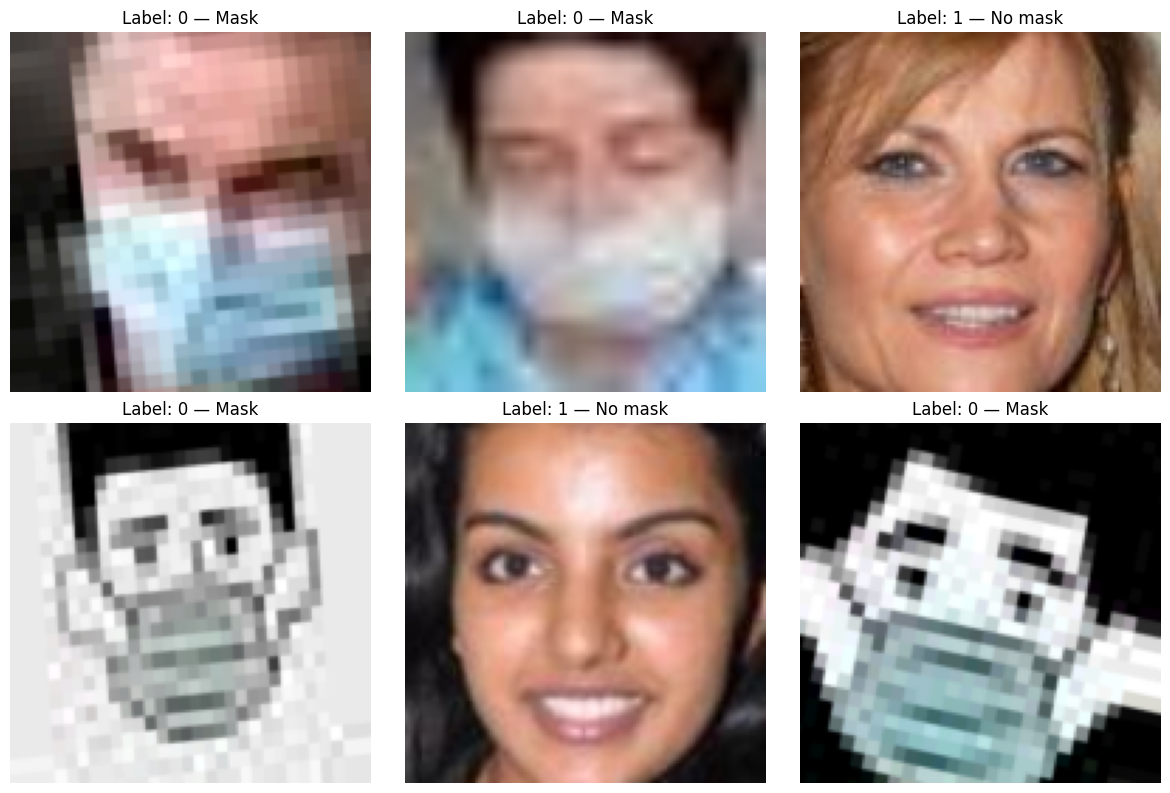

In [15]:
# TODO: answer Question 14, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

# Images information
print("Image-array shape (number of images, RGB channels, height (pixels), width (pixels)):", images.shape)
print("Labels shape:", labels.shape)

print("Pixel range:", images.min(), "to", images.max())

classes, counts = np.unique(labels, return_counts=True)

for label, count in zip(classes, counts):
    class_name = "Mask" if label == 0 else "No mask"
    print(f"Class {label} ({class_name}): {count} images")
    print(f"Class {label}: {count / len(labels):.1%}")


# Plot labelled images
rng = np.random.default_rng(42)
indices = rng.choice(len(images), size=6, replace=False)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, idx in zip(axes.flat, indices):
    
    img = images[idx].transpose(1, 2, 0)

    label = int(labels[idx])
    class_name = "Mask" if label == 0 else "No mask"

    ax.imshow(img.astype(np.uint8))
    ax.set_title(f"Label: {label} — {class_name}")
    ax.axis("off")

plt.tight_layout()
plt.show()

#### 1. Balanced dataset

Both classes are approximately equally represented (53.5% vs 46.5%). Therefore, the dataset is reasonably well balanced.

#### 2. Why do class counts matter when interpreting accuracy ?

Ordinary accuracy is the proportion of correctly predicted samples :

$$
\text{Accuracy} = \frac{\text{Number of correct predictions}}{\text{Total number of images}}
$$

Accuracy can be misleading when the classes are imbalanced. For example, if 90% of the images belong to the "Mask" class, a classifier that always predicts "Mask" achieves 90% accuracy while failing to correctly identify any images in the "No mask" class.

### Question 15 — Feature vectors, split, and baseline

Use `image_features` and report the feature-array shape. Make a stratified 80/20
training/validation split with `random_state=SEED`. Check both class counts.
Fit a majority-class dummy classifier and report training and validation accuracy
and balanced accuracy. Explain why flattening preserves pixel values but does not
give these models explicit spatial structure.

In [16]:
# TODO: answer Question 15, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

# 1. Extract image features
X = image_features(images)
y = labels

print("Feature-array shape:", X.shape)

# 2. Stratified 80/20 training/validation split
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=SEED,
    stratify=y
)

# 3. Check class counts in both sets
print("\nTraining class counts:")
print(dict(zip(*np.unique(y_train, return_counts=True))))

print("\nValidation class counts:")
print(dict(zip(*np.unique(y_val, return_counts=True))))

# 4. Fit a majority-class dummy classifier
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)

# 5. Report training and validation metrics
for name, X_split, y_split in [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val)
]:
    y_pred = dummy.predict(X_split)

    print(f"\n{name} results:")
    print("Accuracy:", accuracy_score(y_split, y_pred))
    print("Balanced accuracy:", balanced_accuracy_score(y_split, y_pred))


Feature-array shape: (185, 3072)

Training class counts:
{np.int64(0): np.int64(79), np.int64(1): np.int64(69)}

Validation class counts:
{np.int64(0): np.int64(20), np.int64(1): np.int64(17)}

Training results:
Accuracy: 0.5337837837837838
Balanced accuracy: 0.5

Validation results:
Accuracy: 0.5405405405405406
Balanced accuracy: 0.5


#### Results and interpretation

The feature array has shape (185, 3072), meaning that each image is represented by 3,072 features. The training set contains 79 class-0 images and 69 class-1 images, while the validation set contains 20 class-0 images and 17 class-1 images. Combining the training and validation sets gives 99 class-0 images and 86 class-1 images, matching the class counts in the original dataset.

The majority-class dummy classifier achieved a training accuracy of 53.38% and a validation accuracy of 54.05%. Its balanced accuracy is 50% on both sets because it always predicts class 0 and therefore fails to identify class 1.

Flattening an image into a feature vector preserves its pixel feature values but does not explicitly encode spatial relationships between neighboring pixels. Consequently, the models treat the features as a vector rather than explicitly modeling the two-dimensional spatial structure of the image.

### Question 16 — Logistic Regression and regularization

Fit Logistic Regression with $\ell_1$ and $\ell_2$ penalties, initially using $C=1$.
Use a `StandardScaler` pipeline and a solver supporting the chosen penalty.
Report training and validation metrics. Explain the difference between the two
penalties and why a single split cannot establish a universal winner.

In [17]:
# TODO: answer Question 16, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

models = {
    "L1": make_pipeline(StandardScaler(), LogisticRegression(penalty="l1", C=1, solver="liblinear", max_iter=2000)),
    "L2": make_pipeline(StandardScaler(), LogisticRegression(penalty="l2", C=1, solver="liblinear", max_iter=2000))
}

for name, model in models.items():
    model.fit(X_train, y_train)

    for split_name, X_split, y_split in [
        ("Training", X_train, y_train),
        ("Validation", X_val, y_val)
    ]:
        y_pred = model.predict(X_split)

        print(f"\n{name} — {split_name}")
        print(f"Accuracy: {accuracy_score(y_split, y_pred):.4f}")
        print(
            f"Balanced accuracy: "
            f"{balanced_accuracy_score(y_split, y_pred):.4f}"
        )

lr_l1 = models["L1"].named_steps["logisticregression"]
lr_l2 = models["L2"].named_steps["logisticregression"]

print("L1 — zero coefficients :", (lr_l1.coef_ == 0).sum())
print("L2 — zero coefficients :", (lr_l2.coef_ == 0).sum())



L1 — Training
Accuracy: 1.0000
Balanced accuracy: 1.0000

L1 — Validation
Accuracy: 0.8919
Balanced accuracy: 0.9000

L2 — Training
Accuracy: 1.0000
Balanced accuracy: 1.0000

L2 — Validation
Accuracy: 0.8649
Balanced accuracy: 0.8750
L1 — zero coefficients : 2994
L2 — zero coefficients : 0


#### Results and interpretation

Both models achieved perfect scores on the training set. On the validation set, L1 performed better than L2, achieving an accuracy of 89.19% and a balanced accuracy of 90.00%, compared with 86.49% and 87.50% for L2. This difference may be related to the number of zero coefficients: L1 set 3,017 coefficients to zero, while L2 set none to zero. This means that L1 uses fewer features, which may help explain its better validation performance.

However, these results are based on a single data split. With a different split, L2 might perform better than L1. Cross-validation would allow us to compare the models across several splits and see which performs more consistently.

### Question 17 — Cross-validate Logistic Regression

Cross-validate penalties `['l1', 'l2']` and seven logarithmically spaced values of
$C$ from $10^{-3}$ to $10^3$. Use the supplied CV/selection convention. Report the
selected parameters, mean CV balanced accuracy and its fold standard deviation,
and validation metrics. Is the tuned model necessarily better on validation than
both models from Question 16? Explain.

In [18]:
# TODO: answer Question 17, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

# Seven values of C, from 10^-3 to 10^3
C_values = np.logspace(-3, 3, 7)

pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(solver="liblinear", max_iter=2000)
)

param_grid = {
    "logisticregression__penalty": ["l1", "l2"],
    "logisticregression__C": C_values
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    scoring="balanced_accuracy",
    cv=5,
    refit=True
)

grid_search.fit(X_train, y_train)

# Best parameters and cross-validation results
print("Best parameters:", grid_search.best_params_)
print("Mean CV balanced accuracy:", grid_search.best_score_)

best_index = grid_search.best_index_
fold_scores = grid_search.cv_results_["split0_test_score"][best_index:best_index+1]
all_fold_scores = np.array([
    grid_search.cv_results_[f"split{i}_test_score"][best_index]
    for i in range(5)
])
print("CV fold standard deviation:", all_fold_scores.std())

# Evaluate the selected model on the validation set
y_val_pred = grid_search.predict(X_val)

print("Validation accuracy:", accuracy_score(y_val, y_val_pred))
print("Validation balanced accuracy:", balanced_accuracy_score(y_val, y_val_pred))

Best parameters: {'logisticregression__C': np.float64(10.0), 'logisticregression__penalty': 'l2'}
Mean CV balanced accuracy: 0.9291071428571429
CV fold standard deviation: 0.03870759694458555
Validation accuracy: 0.8648648648648649
Validation balanced accuracy: 0.875


#### Results and interpretation ???

No, the tuned model is not necessarily better on the validation set because cross-validation selects hyperparameters based on the mean score across the training folds, not on the validation set. Therefore, the selected hyperparameters may not produce the best performance on this separate set. In our results, the tuned model matches the L2 model from Question 16 (86.49% accuracy and 87.50% balanced accuracy) but performs worse than the L1 model (89.19% accuracy and 90.00% balanced accuracy). This illustrates that the best cross-validation score does not guarantee the best validation performance.

### Question 18 — Linear SVM

Fit a scaled linear SVM and cross-validate the same seven values of $C$.
Report selected parameters, CV and validation results, and compare the training
objectives of SVM and Logistic Regression. Keep this comparison empirical: neither
model is required to win. Address convergence warnings if any occur.

In [19]:
# TODO: answer Question 18, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

# Seven candidate values of C
C_values = np.logspace(-3, 3, 7)

# Scaling and linear SVM in one pipeline
svm_pipeline = make_pipeline(
    StandardScaler(),
    LinearSVC(max_iter=10000, random_state=42)
)

param_grid = {"linearsvc__C": C_values}

svm_search = GridSearchCV(
    svm_pipeline,
    param_grid,
    scoring="balanced_accuracy",
    cv=5,
    refit=True
)

svm_search.fit(X_train, y_train)

# Cross-validation results
best_index = svm_search.best_index_
fold_scores = [
    svm_search.cv_results_[f"split{i}_test_score"][best_index]
    for i in range(5)
]

print("Best parameters:", svm_search.best_params_)
print("Mean CV balanced accuracy:", round(float(svm_search.best_score_), 4))
print("CV fold standard deviation:", round(float(np.std(fold_scores)), 4))

# Training and validation results
best_svm = svm_search.best_estimator_
y_train_pred = best_svm.predict(X_train)
y_val_pred = best_svm.predict(X_val)

print("Training accuracy:", round(accuracy_score(y_train, y_train_pred), 4))
print("Training balanced accuracy:",
      round(balanced_accuracy_score(y_train, y_train_pred), 4))
print("Validation accuracy:", round(accuracy_score(y_val, y_val_pred), 4))
print("Validation balanced accuracy:",
      round(balanced_accuracy_score(y_val, y_val_pred), 4))


Best parameters: {'linearsvc__C': np.float64(0.01)}
Mean CV balanced accuracy: 0.9291
CV fold standard deviation: 0.0387
Training accuracy: 1.0
Training balanced accuracy: 1.0
Validation accuracy: 0.8649
Validation balanced accuracy: 0.875


#### Results and interpretation

The best linear SVM was obtained with \(C = 0.01\). Its mean cross-validation balanced accuracy was 92.91%, with a standard deviation of 3.87 percentage points across the five folds.

The SVM achieved 100% training accuracy and 100% training balanced accuracy. On the validation set, it achieved 86.49% accuracy and 87.50% balanced accuracy.

Compared with Logistic Regression, which selected L2 regularization with \(C = 10\), the SVM achieved the same mean cross-validation balanced accuracy and the same validation accuracy and balanced accuracy. Both models also achieved perfect training scores.

However, the two models optimize different objectives. Logistic Regression minimizes regularized logistic loss, while a linear SVM minimizes a regularized hinge-loss objective that encourages a large margin between classes. The parameter \(C\) controls the trade-off between fitting the training data and regularization, but its numerical value is not directly comparable between the two models.

In this experiment, neither model outperformed the other according to the reported metrics. Their identical scores do not imply that they make exactly the same predictions or learn the same decision boundary.

### Question 19 — Random Forest

Train a Random Forest and cross-validate `n_estimators=[30, 100]`,
`max_depth=[10, None]`, and `criterion=['gini', 'entropy']`. Fix its random state.
Report the selected parameters, CV and validation metrics. Explain how this model
differs from the linear models and why increasing depth is not automatically better.

In [20]:
# TODO: answer Question 19, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

rf = RandomForestClassifier(random_state=42)

param_grid = {
    "n_estimators": [30, 100],
    "max_depth": [10, None],
    "criterion": ["gini", "entropy"]
}

rf_search = GridSearchCV(
    rf,
    param_grid,
    scoring="balanced_accuracy",
    cv=5,
    refit=True
)

rf_search.fit(X_train, y_train)

# Cross-validation results for the selected model
best_index = rf_search.best_index_
fold_scores = [
    rf_search.cv_results_[f"split{i}_test_score"][best_index]
    for i in range(5)
]

print("Best parameters:", rf_search.best_params_)
print("Mean CV balanced accuracy:",
      round(float(rf_search.best_score_), 4))
print("CV fold standard deviation:",
      round(float(np.std(fold_scores)), 4))

# Training and validation metrics
best_rf = rf_search.best_estimator_

y_train_pred = best_rf.predict(X_train)
y_val_pred = best_rf.predict(X_val)

print("Training accuracy:",
      round(accuracy_score(y_train, y_train_pred), 4))
print("Training balanced accuracy:",
      round(balanced_accuracy_score(y_train, y_train_pred), 4))
print("Validation accuracy:",
      round(accuracy_score(y_val, y_val_pred), 4))
print("Validation balanced accuracy:",
      round(balanced_accuracy_score(y_val, y_val_pred), 4))


Best parameters: {'criterion': 'entropy', 'max_depth': 10, 'n_estimators': 100}
Mean CV balanced accuracy: 0.8636
CV fold standard deviation: 0.0232
Training accuracy: 1.0
Training balanced accuracy: 1.0
Validation accuracy: 0.8919
Validation balanced accuracy: 0.8956


#### Results and interpretation

The best Random Forest uses 100 trees, a maximum depth of 10, and the entropy criterion. Its mean cross-validation balanced accuracy was 86.36%, with a standard deviation of 2.32 percentage points.

On the validation set, it achieved 89.19% accuracy and 89.56% balanced accuracy.

Unlike Logistic Regression and linear SVM, Random Forest can learn nonlinear patterns by combining multiple decision trees. However, deeper trees can overfit the training data, so increasing depth does not necessarily improve validation performance.

### Question 20 — Compare the original-data models

Compare the tuned Logistic Regression, SVM, and Random Forest in one table of CV,
training, and validation metrics. Explain any train–validation gap. How many
percentage points of ordinary validation accuracy correspond to one image?
Does the table justify claiming that one algorithm is always best?

In [21]:
# TODO: answer Question 20, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

models = {
    "Logistic Regression": grid_search,
    "Linear SVM": svm_search,
    "Random Forest": rf_search
}

results = []

for name, search in models.items():
    model = search.best_estimator_

    y_train_pred = model.predict(X_train)
    y_val_pred = model.predict(X_val)

    results.append({
        "Model": name,
        "CV balanced accuracy (%)": 100 * search.best_score_,
        "Train accuracy (%)": 100 * accuracy_score(y_train, y_train_pred),
        "Train balanced accuracy (%)": 100 * balanced_accuracy_score(y_train, y_train_pred),
        "Validation accuracy (%)": 100 * accuracy_score(y_val, y_val_pred),
        "Validation balanced accuracy (%)": 100 * balanced_accuracy_score(y_val, y_val_pred)
    })

results_df = pd.DataFrame(results).set_index("Model").round(2)
display(results_df)

print(f"One validation image = {100 / len(y_val):.2f} percentage points")


,CV balanced accuracy (%),Train accuracy (%),Train balanced accuracy (%),Validation accuracy (%),Validation balanced accuracy (%)
Model,,,,,
Logistic Regression,92.91,100.0,100.0,86.49,87.50
Linear SVM,92.91,100.0,100.0,86.49,87.50
Random Forest,86.36,100.0,100.0,89.19,89.56


One validation image = 2.70 percentage points


#### Results and interpretation

All three models achieve perfect training accuracy, but lower cross-validation or validation scores. This gap suggests overfitting: the models fit the training data better than they generalize to unseen images.

The validation set contains 37 images, so one misclassified image changes ordinary accuracy by approximately 2.70 percentage points.

Random Forest achieves the highest validation scores, while Logistic Regression and SVM have higher mean cross-validation balanced accuracy. Therefore, these results do not prove that one algorithm is always best; performance depends on the data and the evaluation split.

Additional labelled data have become available in `extra.npz`. The format matches
the original images, but the collection process may have changed its composition.
Inspect it before deciding how to use it. Do not replace the validation or test sets
with this additional dataset. Keep the same feature representation throughout.

### Question 21 — Inspect the extra data

Load `extra.npz`, report its size and class counts, and explain its limitation.
Can it still provide useful training information together with the original
two-class data? Distinguish more observations from more observations of each class.

In [23]:
# TODO: answer Question 21, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

extra = np.load("assets/extra.npz")

print("Available arrays:", extra.files)

X_extra = extra["X"]
y_extra = extra["y"]

print("Images shape:", X_extra.shape)
print("Labels shape:", y_extra.shape)

classes, counts = np.unique(y_extra, return_counts=True)

for cls, count in zip(classes, counts):
    name = "Mask" if cls == 0 else "No mask"
    print(f"Class {cls} ({name}): {count}")

print("Total images:", len(y_extra))

Available arrays: ['X', 'y', 'source_id']
Images shape: (4459, 3, 128, 128)
Labels shape: (4459,)
Class 0 (Mask): 4459
Total images: 4459


???

### Question 22 — Evaluate existing models on extra

Evaluate the already-fitted models from Questions 17–19 on `extra`; **do not refit
them**. Report ordinary accuracy. What class-specific quantity does it estimate?
Can a higher score here than on the two-class validation set establish better
overall classification? Explain why all three fitted models can make these
predictions even though the evaluation labels contain only one class.

In [24]:
# TODO: answer Question 22, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: e

# Load the extra dataset
with np.load("assets/extra.npz") as extra:
    X_extra = extra["X"]
    y_extra = extra["y"]

# Apply the same feature transformation used for training
X_extra_features = image_features(X_extra)

models = {
    "Logistic Regression": grid_search,
    "Linear SVM": svm_search,
    "Random Forest": rf_search,
}

for name, model in models.items():
    y_pred = model.predict(X_extra_features)
    accuracy = accuracy_score(y_extra, y_pred)
    print(f"{name} — extra accuracy: {accuracy:.4f}")

Logistic Regression — extra accuracy: 0.8318
Linear SVM — extra accuracy: 0.8284
Random Forest — extra accuracy: 0.8753


#### Results and interpretation

The accuracy on the extra dataset is 83.18% for Logistic Regression, 82.84% for Linear SVM, and 87.53% for Random Forest. Random Forest achieves the highest accuracy on this dataset.

Since the extra dataset contains only one class, this accuracy estimates the class-specific accuracy for that class. A higher score on extra than on the two-class validation set does not establish better overall classification performance, because the models are not evaluated on both classes.

All three models can make predictions because they were trained on two classes and can predict either class for each input. The fact that the evaluation labels contain only one class does not restrict their predictions; it only affects how their predictions are evaluated.

### Question 23 — What happens with extra-only training?

As a diagnostic, fit a Random Forest with 30 trees on `extra` alone. Predict its
cross-validation accuracy on this dataset, verify it, and evaluate it on the
unchanged two-class validation set. Is hyperparameter tuning useful here?

Explain why fitting Logistic Regression or the linear SVM on `extra` alone is not
a valid alternative. You do not need to trigger an exception. Random Forest is
specified for this diagnostic because it accepts one-class training, **not** because
it must have won Question 22. The next questions combine extra with two-class data.

In [28]:
# TODO: answer Question 23, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

from sklearn.model_selection import cross_val_score

# Load extra
with np.load("assets/extra.npz") as data:
    X_extra = data["X"]
    y_extra = data["y"]

# Use the same feature representation as in previous questions
X_extra_features = image_features(X_extra)

# Check which class is present
print("Classes in extra:", np.unique(y_extra, return_counts=True))

# Random Forest with 30 trees
rf_extra = RandomForestClassifier(
    n_estimators=30,
    random_state=42
)

# Estimate accuracy using cross-validation
cv_scores = cross_val_score(
    rf_extra,
    X_extra_features,
    y_extra,
    cv=5,
    scoring="accuracy"
)

print("CV accuracies:", cv_scores)
print(f"Mean CV accuracy: {cv_scores.mean():.4f}")
print(f"CV standard deviation: {cv_scores.std():.4f}")

# Fit on all of extra
rf_extra.fit(X_extra_features, y_extra)

# Evaluate on the original, unchanged two-class validation set
# X_val must use the same image feature representation
y_val_pred = rf_extra.predict(X_val)

print(f"Validation accuracy: {accuracy_score(y_val, y_val_pred):.4f}")
print(f"Validation balanced accuracy: {balanced_accuracy_score(y_val, y_val_pred):.4f}")
print("Predicted validation classes:", np.unique(y_val_pred, return_counts=True))


Classes in extra: (array([0]), array([4459]))
CV accuracies: [1. 1. 1. 1. 1.]
Mean CV accuracy: 1.0000
CV standard deviation: 0.0000
Validation accuracy: 0.5405
Validation balanced accuracy: 0.5000
Predicted validation classes: (array([0]), array([37]))


#### Results and interpretation

The `extra` dataset contains 4,459 images, all belonging to class 0 (Mask). The Random Forest achieves a cross-validation accuracy of 100% (mean = 1.0000, standard deviation = 0.0000), because every sample in each fold belongs to the same class.

However, when evaluated on the unchanged two-class validation set, the model predicts class 0 for all 37 images. Its accuracy is 54.05%, while its balanced accuracy is 50%. This shows that training on only one class does not produce a useful classifier for distinguishing between Mask and No mask.

Hyperparameter tuning is not useful here because the training data contains only one class, so the model cannot learn to distinguish between the two classes. Logistic Regression and the linear SVM are not valid alternatives because they require at least two classes during training.

### Question 24 — Combine the training data

Join **only the internal training portion** of `train.npz` with `extra`.
Keep validation untouched. Report counts and majority-class accuracy. Repeat the
Random Forest search from Question 19, selecting by balanced accuracy, and report
CV accuracy, CV balanced accuracy, and validation metrics. Explain why a high
ordinary accuracy on the combined distribution may be misleading. Do not report
resubstitution accuracy as generalization performance.

In [29]:
# TODO: answer Question 24, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

# Combine only the internal training data with extra
X_combined = np.concatenate((X_train, X_extra_features), axis=0)
y_combined = np.concatenate((y_train, y_extra), axis=0)

# Class counts
classes, counts = np.unique(y_combined, return_counts=True)

print("Combined dataset:")
for cls, count in zip(classes, counts):
    print(f"Class {cls}: {count} images")

print("Total:", len(y_combined))

# Majority-class baseline
majority_accuracy = counts.max() / counts.sum()
print(f"Majority-class accuracy: {majority_accuracy:.4f}")

# Random Forest 
rf = RandomForestClassifier(random_state=42)

rf_search_combined = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring={
        "accuracy": "accuracy",
        "balanced_accuracy": "balanced_accuracy"
    },
    refit="balanced_accuracy",
    cv=5,
    return_train_score=True
)

rf_search_combined.fit(X_combined, y_combined)

best_index = rf_search_combined.best_index_

print("Best parameters:", rf_search_combined.best_params_)
print(f"CV accuracy: {rf_search_combined.cv_results_['mean_test_accuracy'][best_index]:.4f}")
print(f"CV balanced accuracy: {rf_search_combined.best_score_:.4f}")

# Validation metrics on the original validation set
y_val_pred = rf_search_combined.predict(X_val)

print(f"Validation accuracy: {accuracy_score(y_val, y_val_pred):.4f}")
print(f"Validation balanced accuracy: {balanced_accuracy_score(y_val, y_val_pred):.4f}")

print("Predicted validation classes:", np.unique(y_val_pred, return_counts=True))

Combined dataset:
Class 0: 4538 images
Class 1: 69 images
Total: 4607
Majority-class accuracy: 0.9850
Best parameters: {'criterion': 'entropy', 'max_depth': 10, 'n_estimators': 30}
CV accuracy: 0.9865
CV balanced accuracy: 0.5516
Validation accuracy: 0.6486
Validation balanced accuracy: 0.6176
Predicted validation classes: (array([0, 1]), array([33,  4]))


#### Results and interpretation

After combining the internal training data with the extra dataset, the resulting training set contains 4,538 Mask images (class 0) and only 69 No mask images (class 1). It is therefore strongly imbalanced, with a majority-class baseline accuracy of 98.50%.

Ordinary accuracy can be misleading in this situation because a model can achieve a high score by mainly predicting the majority class, without correctly identifying the minority class. Indeed, the Random Forest achieves 98.65% cross-validation accuracy but only 55.16% balanced accuracy.

For this reason, the Random Forest is selected using cross-validation balanced accuracy, which gives equal importance to both classes. On the unchanged two-class validation set, the model achieves 64.86% accuracy and 61.76% balanced accuracy. It predicts 33 images as Mask and only 4 as No mask. These results provide a more meaningful evaluation of its ability to distinguish between Mask and No mask images.

### Question 25 — Oversampling inside Random Forest cross-validation

Implement random oversampling of the minority class with replacement to match
the majority count. Repeat the Random Forest search using stratified folds:
oversample **each training fold only**, fit on it, and score the untouched validation
fold. After selection, oversample the full combined training set and refit.
Report CV and external validation metrics, including no-mask recall.

You may write a manual CV loop or a scikit-learn-compatible estimator whose `fit`
resamples and whose `predict` does not. Explain why oversampling before splitting
into CV folds leaks information and why duplicating images does not create new
independent observations. Keep a fixed resampling seed for comparable candidates.

In [31]:
# TODO: answer Question 25, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, ParameterGrid
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score
)

# Random oversampling with replacement
def oversample_minority(X, y, random_state=42):
    rng = np.random.RandomState(random_state)

    classes, counts = np.unique(y, return_counts=True)
    majority_count = counts.max()

    indices = np.arange(len(y))
    sampled_indices = list(indices)

    for cls, count in zip(classes, counts):
        if count < majority_count:
            class_indices = indices[y == cls]
            extra_indices = rng.choice(
                class_indices,
                size=majority_count - count,
                replace=True
            )
            sampled_indices.extend(extra_indices)

    sampled_indices = np.array(sampled_indices)
    rng.shuffle(sampled_indices)

    return X[sampled_indices], y[sampled_indices]


# Stratified cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []

for params in ParameterGrid(param_grid):
    fold_accuracies = []
    fold_balanced_accuracies = []

    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X_combined, y_combined)
    ):
        X_fold_train = X_combined[train_idx]
        y_fold_train = y_combined[train_idx]

        X_fold_val = X_combined[val_idx]
        y_fold_val = y_combined[val_idx]

        # Oversample ONLY the training fold
        X_resampled, y_resampled = oversample_minority(
            X_fold_train,
            y_fold_train,
            random_state=42
        )

        model = RandomForestClassifier(
            **params,
            random_state=42
        )

        model.fit(X_resampled, y_resampled)

        y_fold_pred = model.predict(X_fold_val)

        fold_accuracies.append(
            accuracy_score(y_fold_val, y_fold_pred)
        )

        fold_balanced_accuracies.append(
            balanced_accuracy_score(y_fold_val, y_fold_pred)
        )

    results.append({
        "params": params,
        "mean_accuracy": np.mean(fold_accuracies),
        "mean_balanced_accuracy": np.mean(fold_balanced_accuracies),
        "std_balanced_accuracy": np.std(fold_balanced_accuracies)
    })


# Select the best model using balanced accuracy
best_result = max(
    results,
    key=lambda result: result["mean_balanced_accuracy"]
)

best_params = best_result["params"]

print("Best parameters:", best_params)
print(f"CV accuracy: {best_result['mean_accuracy']:.4f}")
print(f"CV balanced accuracy: {best_result['mean_balanced_accuracy']:.4f}")


# Oversample the FULL combined training set and refit
X_resampled, y_resampled = oversample_minority(
    X_combined,
    y_combined,
    random_state=42
)

best_model = RandomForestClassifier(
    **best_params,
    random_state=42
)

best_model.fit(X_resampled, y_resampled)


# Evaluate on the ORIGINAL, untouched validation set
y_val_pred = best_model.predict(X_val)

print(f"Validation accuracy: {accuracy_score(y_val, y_val_pred):.4f}")
print(f"Validation balanced accuracy: {balanced_accuracy_score(y_val, y_val_pred):.4f}")

# Class 1 = No mask
no_mask_recall = recall_score(
    y_val,
    y_val_pred,
    pos_label=1,
    zero_division=0
)

print(f"No-mask recall: {no_mask_recall:.4f}")

Best parameters: {'criterion': 'gini', 'max_depth': 10, 'n_estimators': 100}
CV accuracy: 0.9774
CV balanced accuracy: 0.7548
CV balanced accuracy std: 0.0858
Validation accuracy: 0.8919
Validation balanced accuracy: 0.8912
No-mask recall: 0.8824


#### Results and interpretation

Oversampling before splitting into cross-validation folds would cause data leakage, because duplicated images could appear in both the training and validation folds. This would lead to overly optimistic performance estimates. Furthermore, duplicating images does not create new independent observations or provide additional visual information.

The best Random Forest uses the Gini criterion, a maximum depth of 10, and 100 trees. It achieves a cross-validation accuracy of 97.74% and a balanced accuracy of 75.48% (standard deviation: 0.0858).

On the unchanged validation set, the model achieves 89.19% accuracy and 89.12% balanced accuracy. The recall for the No mask class is 88.24%.

Compared with Question 24, oversampling substantially improves balanced accuracy on both cross-validation and validation data. In particular, the high No-mask recall indicates that the model is now much better at identifying images without masks. This shows that oversampling helps reduce the negative effect of class imbalance.

### Question 26 — Oversampling with Logistic Regression

Repeat Question 25 using a scaled Logistic Regression with an $\ell_2$ penalty
and $C\in\{0.01,0.1,1,10,100\}$. Keep oversampling within each training fold,
including during hyperparameter selection. Compare with the oversampled forest
and the original-data Logistic Regression. Do not assume the ordering in advance.

In [32]:
# TODO: answer Question 26, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

C_values = [0.01, 0.1, 1, 10, 100]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []

for C in C_values:
    fold_accuracies = []
    fold_balanced_accuracies = []

    for train_idx, val_idx in cv.split(X_combined, y_combined):
        X_fold_train = X_combined[train_idx]
        y_fold_train = y_combined[train_idx]

        X_fold_val = X_combined[val_idx]
        y_fold_val = y_combined[val_idx]

        # Oversampling only on the training fold
        X_resampled, y_resampled = oversample_minority(
            X_fold_train, y_fold_train, random_state=42
        )

        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                penalty="l2",
                C=C,
                max_iter=2000,
                random_state=42
            )
        )

        model.fit(X_resampled, y_resampled)
        y_pred = model.predict(X_fold_val)

        fold_accuracies.append(accuracy_score(y_fold_val, y_pred))
        fold_balanced_accuracies.append(
            balanced_accuracy_score(y_fold_val, y_pred)
        )

    results.append({
        "C": C,
        "mean_accuracy": np.mean(fold_accuracies),
        "mean_balanced_accuracy": np.mean(fold_balanced_accuracies)
    })

# Select best C using balanced accuracy
best_result = max(
    results,
    key=lambda result: result["mean_balanced_accuracy"]
)

best_C = best_result["C"]

print("Results for each C:")
for result in results:
    print(result)

print("\nBest C:", best_C)
print(f"CV accuracy: {best_result['mean_accuracy']:.4f}")
print(f"CV balanced accuracy: {best_result['mean_balanced_accuracy']:.4f}")

# Oversample the full combined training set
X_resampled, y_resampled = oversample_minority(
    X_combined, y_combined, random_state=42
)

# Refit the best model
best_lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        penalty="l2",
        C=best_C,
        max_iter=2000,
        random_state=42
    )
)

best_lr_model.fit(X_resampled, y_resampled)

# Evaluate on unchanged validation set
y_val_pred = best_lr_model.predict(X_val)

print(f"\nValidation accuracy: {accuracy_score(y_val, y_val_pred):.4f}")
print(f"Validation balanced accuracy: {balanced_accuracy_score(y_val, y_val_pred):.4f}")

print(f"No-mask recall: {recall_score(y_val, y_val_pred, pos_label=1):.4f}")

Results for each C:
{'C': 0.01, 'mean_accuracy': np.float64(0.9780767391852201), 'mean_balanced_accuracy': np.float64(0.8482187524068101)}
{'C': 0.1, 'mean_accuracy': np.float64(0.9815498102835502), 'mean_balanced_accuracy': np.float64(0.8283343342638643)}
{'C': 1, 'mean_accuracy': np.float64(0.9828510931954092), 'mean_balanced_accuracy': np.float64(0.8219617951078835)}
{'C': 10, 'mean_accuracy': np.float64(0.9752534852007038), 'mean_balanced_accuracy': np.float64(0.8251379517470712)}
{'C': 100, 'mean_accuracy': np.float64(0.9739507891309314), 'mean_balanced_accuracy': np.float64(0.8168944975632074)}

Best C: 0.01
CV accuracy: 0.9781
CV balanced accuracy: 0.8482

Validation accuracy: 0.9459
Validation balanced accuracy: 0.9412
No-mask recall: 0.8824




| Model | CV Balanced Accuracy | Validation Accuracy | Validation Balanced Accuracy |
|---|---:|---:|---:|
| Original Logistic Regression (Q17) | 92.91% | 86.49% | 87.50% |
| Oversampled Random Forest (Q25) | 75.48% | 89.19% | 89.12% |
| Oversampled Logistic Regression (Q26) | 84.82% | **94.59%** | **94.12%** |

#### Results and interpretation

The model achieved a cross-validation accuracy of 97.81% and a balanced accuracy of 84.82% with C = 0.01.

On the unchanged validation set, it achieved 94.59% accuracy, 94.12% balanced accuracy, and 88.24% No-mask recall.

Compared with the original Logistic Regression and the oversampled Random Forest, the oversampled Logistic Regression achieved the best validation accuracy and balanced accuracy. Its cross-validation balanced accuracy was also higher than that of the oversampled Random Forest, although lower than that of the original Logistic Regression.

These results show that oversampling can substantially improve validation performance in this case, but its effect depends on the model and the evaluation metric.

### Question 27 — Choose and justify a final model

Compare the three combined-data procedures from Questions 24–26 using their CV
balanced accuracy and unchanged validation metrics. Select a final procedure by
CV balanced accuracy; use validation for interpretation rather than repeatedly
tuning to it. Describe the method, selected parameters, and trade-offs.

For an optional extension, try at most one additional clearly specified procedure
(for example class weighting) under exactly the same CV protocol. A larger search
or higher score is not required for full credit. Do not access the final test data.

#### Answer 

Among the three combined-data procedures, the oversampled Logistic Regression (Q26) is selected as the final procedure because it achieves the highest cross-validation balanced accuracy (84.82%).

This procedure combines the internal training data with the extra dataset, applies random oversampling with replacement within each training fold, and uses a StandardScaler followed by an L2-regularized Logistic Regression. The best hyperparameter is C = 0.01.

For comparison, the Random Forest with oversampling (Q25) achieves a CV balanced accuracy of 75.48%, while the procedure without oversampling (Q24) achieves only 55.16%.

On the unchanged validation set, the selected Logistic Regression achieves 94.59% accuracy and 94.12% balanced accuracy, with a No-mask recall of 88.24%. These results indicate good performance on both classes.

The main trade-off is that oversampling duplicates minority-class images rather than introducing new independent observations. This can increase the influence of minority-class samples but does not add new visual information. The final choice is based on cross-validation balanced accuracy, while validation results are used to assess and interpret its performance.

#### Optional

In [35]:
# TODO: answer Question 27, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 

# Optional 

# Same stratified CV protocol
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Random Forest with balanced class weights
rf_weighted = RandomForestClassifier(
    class_weight="balanced",
    random_state=42
)

# Hyperparameter search
rf_weighted_search = GridSearchCV(
    estimator=rf_weighted,
    param_grid=param_grid,
    scoring={
        "accuracy": "accuracy",
        "balanced_accuracy": "balanced_accuracy"
    },
    refit="balanced_accuracy",
    cv=cv,
    return_train_score=True
)

rf_weighted_search.fit(X_combined, y_combined)

# Best parameters and CV results
best_index = rf_weighted_search.best_index_

print("Best parameters:", rf_weighted_search.best_params_)
print(f"CV accuracy: {rf_weighted_search.cv_results_['mean_test_accuracy'][best_index]:.4f}")
print(f"CV balanced accuracy: {rf_weighted_search.best_score_:.4f}")

# Evaluate on unchanged validation set
y_val_pred = rf_weighted_search.predict(X_val)

print(f"Validation accuracy: {accuracy_score(y_val, y_val_pred):.4f}")
print(f"Validation balanced accuracy: {balanced_accuracy_score(y_val, y_val_pred):.4f}")

print(f"No-mask recall: {recall_score(y_val, y_val_pred, pos_label=1):.4f}")

Best parameters: {'criterion': 'entropy', 'max_depth': 10, 'n_estimators': 100}
CV accuracy: 0.9889
CV balanced accuracy: 0.6887
Validation accuracy: 0.8919
Validation balanced accuracy: 0.8824
No-mask recall: 0.7647


As an optional extension, a Random Forest with `class_weight="balanced"` was evaluated without oversampling. The best parameters were `criterion="entropy"`, `max_depth=10`, and `n_estimators=100`.

The model achieved a cross-validation accuracy of 98.89% and a balanced accuracy of 68.87%. On the unchanged validation set, it achieved 89.19% accuracy, 88.24% balanced accuracy, and 76.47% No-mask recall.

Although class weighting improves performance compared with using no imbalance correction, it performs worse than random oversampling in this experiment. In particular, its cross-validation balanced accuracy and No-mask recall are lower than those of the oversampled Random Forest.

Therefore, the optional experiment does not change the final model selection. The oversampled Logistic Regression from Question 26 remains the preferred procedure, based on its highest cross-validation balanced accuracy of 84.82%.


### Question 28 — Error costs (optional)

Suppose missing a person without a mask is more costly than falsely flagging a
masked person. Explain how class weights or a decision threshold could reflect
this. As a small diagnostic, compare weights `{0: 1, 1: 1}` and `{0: 1, 1: 3}` in
a Random Forest using the parameters from Question 24. Report both class recalls
on validation. Do not claim that a weight of 3 guarantees a specified recall or
implements a calibrated cost-optimal policy. Keep Question 27's final selection
fixed for the standard benchmark in Question 29.

In [36]:
# TODO: answer Question 28, including the requested reasoning and code.
# YOUR CODE HERE
# Written answer: 


weights_to_test = [
    {0: 1, 1: 1},
    {0: 1, 1: 3}
]

for weights in weights_to_test:
    model = RandomForestClassifier(
        criterion="entropy",
        max_depth=10,
        n_estimators=30,
        class_weight=weights,
        random_state=42
    )

    model.fit(X_combined, y_combined)
    y_pred = model.predict(X_val)

    recall_mask = recall_score(y_val, y_pred, pos_label=0)
    recall_no_mask = recall_score(y_val, y_pred, pos_label=1)

    print(f"Weights: {weights}")
    print(f"Mask recall: {recall_mask:.4f}")
    print(f"No-mask recall: {recall_no_mask:.4f}")
    print()

Weights: {0: 1, 1: 1}
Mask recall: 1.0000
No-mask recall: 0.2353

Weights: {0: 1, 1: 3}
Mask recall: 1.0000
No-mask recall: 0.2941



#### Results and interpretation

Giving a higher weight to class 1 (No mask) makes misclassifying a person without a mask more costly during training. This can encourage the Random Forest to identify more images without masks and potentially increase the recall for class 1. However, it may also increase false positives for class 0 (Mask).

The results show that increasing the weight of class 1 from 1 to 3 improves its validation recall from 23.53% to 29.41%, while the recall for class 0 remains unchanged at 100%. This suggests that the higher weight helps the model identify slightly more people without masks. However, the improvement is modest, and the model still misses many No-mask images.

A weight of 3 does not guarantee a specific recall or represent a calibrated cost-optimal policy. It simply changes the relative importance of the two classes during training.

### Question 29 — Freeze, refit, and evaluate once

Freeze the procedure and hyperparameters selected in Question 27. Refit on all of
`train.npz` plus `extra.npz`, now including the development validation observations.
Use resampling only if it belongs to your selected procedure. Then, for the first
time, evaluate on `test.npz` using `evaluate` and display a confusion matrix.

Compare final test metrics with your development estimates. Explain why scores
can change without an implementation error, why duplication did not increase the
number of independent no-mask examples, and why you must not select a replacement
model using this final test result. State important limitations of this experiment.

Final development data shape: (4681, 3072)
Final label shape: (4681,)
Class counts: (array([0, 1]), array([4578,  103]))
Final test metrics: {'accuracy': 0.851118760757315, 'balanced_accuracy': 0.8521816932119832, 'recall_no_mask': 0.7286689419795221}


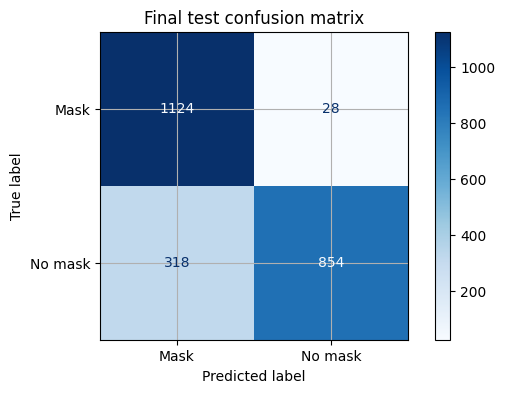

In [42]:
# Question 29 — Freeze, refit, and evaluate once

# 1. Load the complete development training data
X_train_images, y_train_all = load_file("train")
X_extra_images, y_extra = load_file("extra")

# 2. Apply the provided feature extraction to all images
X_train_all = image_features(X_train_images)
X_extra_features = image_features(X_extra_images)

# X_val already contains the features extracted in Question 15.
# Combine all development data, including the previous validation set.
X_final = np.concatenate(
    [X_train_all, X_extra_features, X_val],
    axis=0
)

y_final = np.concatenate(
    [y_train_all, y_extra, y_val],
    axis=0
)

print("Final development data shape:", X_final.shape)
print("Final label shape:", y_final.shape)
print("Class counts:", np.unique(y_final, return_counts=True))

# 3. Oversample the minority class (as in the selected Q27 procedure)
X_final_over, y_final_over = oversample_minority(
    X_final, y_final, random_state=42
)

# 4. Refit the frozen Q27 model
final_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        penalty="l2",
        C=0.01,
        max_iter=2000,
        random_state=42
    )
)

final_model.fit(X_final_over, y_final_over)

# 5. Load the final test set only now
X_test_images, y_test = load_file("test")
X_test_features = image_features(X_test_images)

# 6. Evaluate exactly once using the provided evaluator
evaluate(final_model)

# 7. Display the confusion matrix
y_test_pred = final_model.predict(X_test_features)

cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Mask", "No mask"]
)

disp.plot(cmap="Blues")
plt.title("Final test confusion matrix")
plt.show()

### Results and interpretation

The final model achieved an accuracy of **85.11%** and a balanced accuracy of **85.22%** on the test set. Its recall for the No mask class was **72.87%**.

Compared with the development estimates, the test balanced accuracy (85.22%) is very close to the cross-validation balanced accuracy (84.82%), differing by only 0.40 percentage points. However, it is lower than the validation balanced accuracy (94.12%) by 8.90 percentage points. The test accuracy is also lower than the validation accuracy (94.59%).

These differences do not necessarily indicate an implementation error. The validation and test sets contain different images, and performance can vary depending on the specific examples in each set. This is particularly relevant because the original dataset is small and the validation set contains relatively few observations. Cross-validation also provides an average over several splits, whereas the test score comes from one fixed set.

Oversampling increased the number of No mask training observations by duplicating existing images. It did not create new, independent examples or introduce new visual information. Therefore, the effective diversity of the No mask training data remained limited.

The final test results must not be used to select a replacement model or tune its hyperparameters. The test set is intended for an unbiased final evaluation. Making further model choices based on its results would introduce test-set leakage and make the reported performance less reliable.

**Important limitations of this experiment:**
- The original dataset is small, which limits the reliability and generalisability of the results.
- The training data is strongly imbalanced: the final development set contains 4,578 Mask images and only 103 No mask images before oversampling.
- Oversampling duplicates existing observations rather than providing genuinely new examples.
- The model still misses some No mask images: 318 out of 1,172 were classified as Mask.
- The experiment uses a limited image representation and may not capture all relevant visual features.
- The dataset may not represent the full range of real-world conditions, such as different lighting, camera angles, face coverings and backgrounds.

Overall, the test balanced accuracy is consistent with the cross-validation estimate, but the No mask recall shows that the model still has difficulty detecting this class. Its performance should therefore be interpreted cautiously, especially before considering real-world deployment.

Before submission, restart the kernel and run your notebook in order. Check that
every required question has an explanation, every figure is labelled, and your
reported conclusions match your actual outputs. Include a short account of any
AI assistance and the checks you performed. Keep the final-test result as the
assessment of your frozen procedure rather than using it for another tuning cycle.